# 01 · Time series EDA

What this notebook answers, in order:

1. How total sales move over time: trend, weekly and yearly seasonality, paydays, holidays, the 2016 earthquake, Christmas closures.
2. How sales split by family and by store, which series are always zero, and which stores and families start late.
3. What the target's distribution looks like, and why log1p + RMSLE.
4. What promotions, oil and transactions tell us, and which of them are actually known for the 16 forecast days.
5. STL/MSTL decomposition, stationarity tests (ADF, KPSS) and ACF/PACF, on the total and across all series.

The EDA uses all the training data, including the four backtest windows. That's fine for coarse decisions (use log1p, model the weekly pattern, handle holidays), but nothing here should pick a precise setting by looking at how the validation windows behave. Tuning happens on the folds, later.

Centred rolling means appear in this notebook only to describe the data. They use future days, so they can never become features.

In [1]:
import sys, time, warnings
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from cycler import cycler
from statsmodels.tsa.seasonal import MSTL
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tools.sm_exceptions import InterpolationWarning

from src import cv, features

T0 = time.perf_counter()
cv.set_seed()
cv.ensure_dirs()
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

# Chart style: one light surface, recessive grid, fixed categorical order
SURFACE, INK, INK2, GRID, NEUTRAL = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e0", "#a9a8a2"
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
BLUE, ORANGE = PALETTE[0], PALETTE[1]
SEQ = LinearSegmentedColormap.from_list("seq_blue", ["#f0efec", "#9ec5f4", "#3987e5", "#1c5cab", "#0d366b"])
DIV = LinearSegmentedColormap.from_list("div_blue_red", ["#104281", "#86b6ef", "#f0efec", "#ef9a99", "#a8302f"])
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": NEUTRAL, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.prop_cycle": cycler(color=PALETTE),
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "lines.linewidth": 1.6, "legend.frameon": False, "figure.dpi": 110, "axes.axisbelow": True,
})

def save(fig, name):
    """Save to reports/figures with the phase prefix."""
    fig.savefig(cv.FIGURES / f"01_{name}.png", dpi=130, bbox_inches="tight")

def mark(ax, date, label):
    """Dashed vertical line with a small label for a one-off event."""
    ax.axvline(date, color=INK2, lw=1, ls="--")
    ax.text(date, 0.98, f" {label}", transform=ax.get_xaxis_transform(), color=INK2, fontsize=9, va="top")

SUMMARY = {}   # key numbers, collected for the findings at the end

Setup only: imports, chart style, and the `save` and `mark` helpers. Every figure goes to reports/figures with the 01_ prefix.

## 0 · Load

In [2]:
train = cv.read_raw("train")
test = cv.read_raw("test")
stores = cv.read_raw("stores")
oil = cv.read_raw("oil")
hol = cv.read_raw("holidays")
trans = cv.read_raw("transactions")

CAL = features.full_calendar()                                   # every day, Dec 25 included
total = train.groupby("date")["sales"].sum().reindex(CAL)        # NaN on Dec 25: no rows that day
W = features.wide_sales(train)                                   # dates x 1,782 series, full calendar
ST = train.groupby(["date", "store_nbr"])["sales"].sum().unstack().reindex(CAL)   # dates x 54 stores
log_total = np.log(total.where(total > 0))

print("W (dates x series):", W.shape, "| ST (dates x stores):", ST.shape)
print("days with no data:", [d.date() for d in total[total.isna()].index])

W (dates x series): (1688, 1782) | ST (dates x stores): (1688, 54)
days with no data: [datetime.date(2013, 12, 25), datetime.date(2014, 12, 25), datetime.date(2015, 12, 25), datetime.date(2016, 12, 25)]


The wide matrix is 1,688 days × 1,782 series. That's every calendar day, so the four Christmas Days are NaN rows instead of missing rows. Because of that, shifting by k rows is exactly k days, which is what the lag features in Phase 2 need.

## 1 · Total sales over time: trend

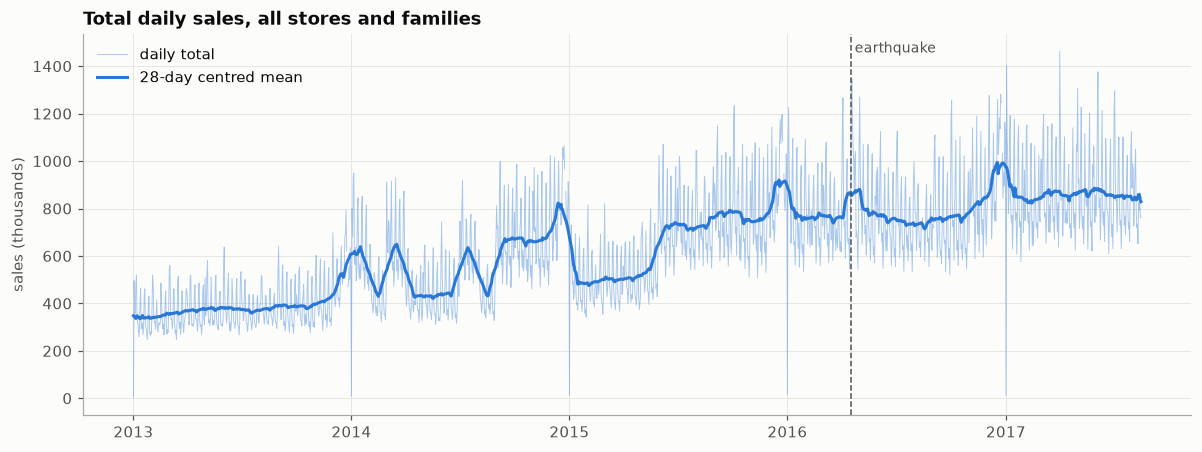

       mean_daily  days  growth_%
2013 385,766.5218   364       NaN
2014 575,478.6986   364   49.1780
2015 661,758.5183   364   14.9927
2016 790,834.3095   365   19.5050
2017 855,581.7990   227    8.1872

(2017 only runs to Aug 15 and has no December, so its mean is not directly comparable.)

lowest-sales days:
2013-01-01     2.5000
2014-01-01     8.6000
2017-01-01    12.1000
2015-01-01    12.8000
2016-01-01    16.4000
2013-01-24   247.2000
2013-03-14   247.5000
2013-01-10   259.0000


In [3]:
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(total.index, total / 1e3, color=BLUE, lw=0.6, alpha=0.4, label="daily total")
ax.plot(total.index, total.rolling(28, center=True, min_periods=14).mean() / 1e3,
        color=BLUE, lw=2, label="28-day centred mean")
mark(ax, pd.Timestamp("2016-04-16"), "earthquake")
ax.set(title="Total daily sales, all stores and families", ylabel="sales (thousands)")
ax.legend(loc="upper left")
save(fig, "total_sales")
plt.show()

yearly = total.groupby(total.index.year).agg(mean_daily="mean", days="count")
yearly["growth_%"] = yearly["mean_daily"].pct_change() * 100
print(yearly)
print("\n(2017 only runs to Aug 15 and has no December, so its mean is not directly comparable.)")
print("\nlowest-sales days:")
print((total.nsmallest(8) / 1e3).round(1).rename("sales (thousands)").to_string())
SUMMARY["mean daily sales 2016 / 2013"] = round(float(yearly.loc[2016, "mean_daily"] / yearly.loc[2013, "mean_daily"]), 2)

The jumps in this plot matter more than the trend. There's a flat 2013, a jump at the start of 2014, three humps in 2014, a drop in early 2015, and a step up around mid-2015. From mid-2015 on the series looks like a normal retail series: a slow rise, a December peak and Jan 1 near zero.

The "+49% growth" from 2013 to 2014 is not real growth. The family heatmap further down shows that ten families have no sales recorded at all in 2013, and in 2014 and early 2015 they switch on and off month by month. PRODUCE alone is 11% of all sales. So the humps and steps come from data coverage, not demand, and mean daily sales 2.05× higher in 2016 than in 2013 overstates the real growth.

The lowest days are the five Jan 1sts (2.5k–16k against a normal day of 600–900k). Stores are closed.

## 2 · Weekly seasonality

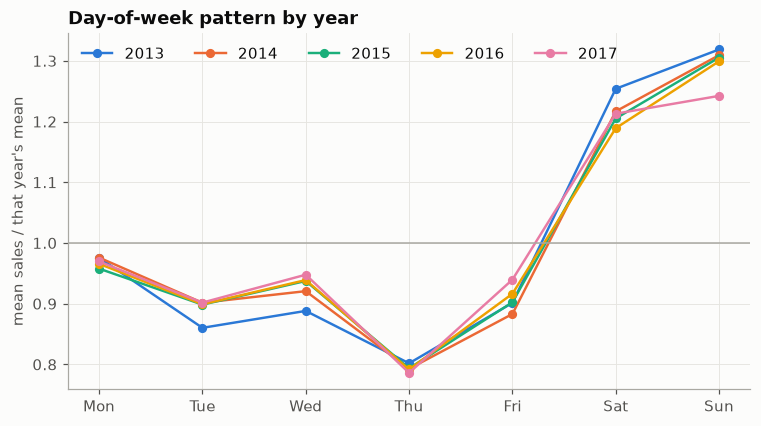

          0      1      2      3      4      5      6
2013 0.9760 0.8600 0.8880 0.8020 0.9010 1.2540 1.3190
2014 0.9760 0.9020 0.9210 0.7930 0.8830 1.2170 1.3090
2015 0.9580 0.8980 0.9370 0.7940 0.9020 1.2050 1.3050
2016 0.9660 0.8990 0.9390 0.7920 0.9160 1.1890 1.2990
2017 0.9700 0.9020 0.9480 0.7860 0.9400 1.2130 1.2420


In [4]:
dow = total.groupby([total.index.year, total.index.day_of_week]).mean().unstack()
dow_ratio = dow.div(dow.mean(axis=1), axis=0)
days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

fig, ax = plt.subplots(figsize=(8, 4.2))
for i, (yr, row) in enumerate(dow_ratio.iterrows()):
    ax.plot(range(7), row.to_numpy(), marker="o", ms=5, color=PALETTE[i], label=str(yr))
ax.axhline(1, color=NEUTRAL, lw=1)
ax.set_xticks(range(7), days)
ax.set(title="Day-of-week pattern by year", ylabel="mean sales / that year's mean")
ax.legend(ncol=5, loc="upper left")
save(fig, "weekday_by_year")
plt.show()
print(dow_ratio.round(3))
SUMMARY["weekday range (max/min), last full year"] = round(dow_ratio.loc[2016].max() / dow_ratio.loc[2016].min(), 2)

The weekly pattern is strong and very stable across years. Sunday is the best day (about 1.30× the weekly mean), then Saturday (about 1.20×), and Thursday is the weakest (about 0.79×). Max/min is 1.64 in 2016. Sunday is a little weaker in 2017 (1.24), and I'll keep an eye on that.

A shape this stable means day of week is the first feature every model needs.

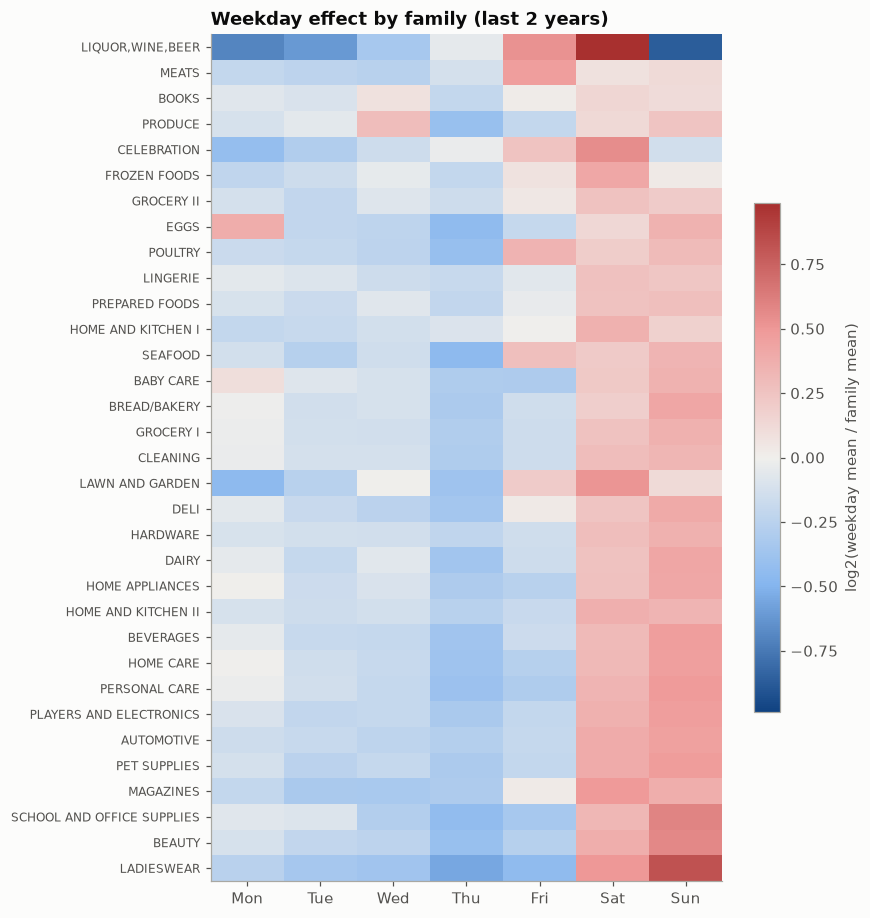

In [5]:
# Weekday pattern by family, last two years only (the current pattern matters most)
recent = train[train["date"] > cv.TRAIN_END - pd.Timedelta(days=730)]
fd = recent.groupby(["family", recent["date"].dt.day_of_week])["sales"].mean().unstack()
fd = fd[fd.mean(axis=1) > 0]
fd_log = np.log2(fd.div(fd.mean(axis=1), axis=0).clip(lower=1e-3))
fd_log = fd_log.loc[fd_log[[5, 6]].mean(axis=1).sort_values().index]   # sort by weekend effect
v = float(np.nanmax(np.abs(fd_log.to_numpy())))

fig, ax = plt.subplots(figsize=(7.5, 10))
im = ax.imshow(fd_log.to_numpy(), cmap=DIV, vmin=-v, vmax=v, aspect="auto")
ax.set_xticks(range(7), days)
ax.set_yticks(range(len(fd_log)), fd_log.index, fontsize=8)
ax.grid(False)
ax.set_title("Weekday effect by family (last 2 years)")
cb = fig.colorbar(im, ax=ax, shrink=0.6)
cb.set_label("log2(weekday mean / family mean)")
save(fig, "weekday_by_family")
plt.show()

Most families share the same weekend pattern, but not all of them. LIQUOR,WINE,BEER is the clear exception: Saturday is its strongest day and Sunday its weakest, the opposite of everything else. EGGS is unusually strong on Monday, MEATS on Friday, and LADIESWEAR and SCHOOL AND OFFICE SUPPLIES have the biggest Sunday lift.

So one weekday effect for everything would be wrong for some families. A linear model needs day-of-week × family terms; a tree model can find this itself.

## 3 · Yearly seasonality and the end of the year

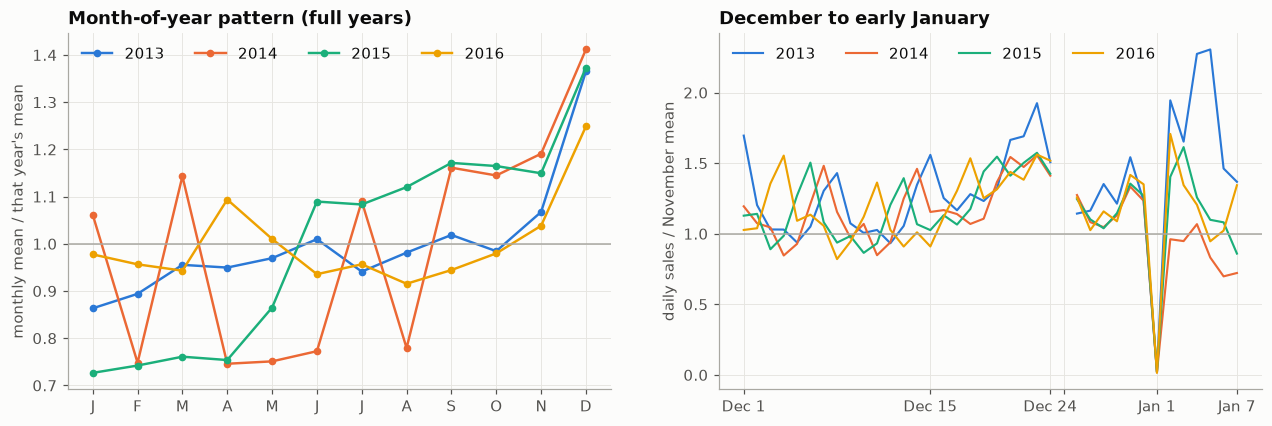

         1      2      3      4      5      6      7      8      9      10     11     12
2013 0.8630 0.8940 0.9550 0.9500 0.9700 1.0100 0.9410 0.9810 1.0190 0.9840 1.0670 1.3650
2014 1.0610 0.7480 1.1430 0.7460 0.7510 0.7730 1.0900 0.7790 1.1610 1.1450 1.1910 1.4120
2015 0.7270 0.7420 0.7610 0.7540 0.8650 1.0890 1.0830 1.1200 1.1710 1.1650 1.1490 1.3730
2016 0.9780 0.9570 0.9430 1.0940 1.0100 0.9360 0.9570 0.9150 0.9440 0.9800 1.0380 1.2490


In [6]:
m = total.groupby([total.index.year, total.index.month]).mean().unstack()
m_ratio = m.loc[[y for y in m.index if y < 2017]]                  # full years only
m_ratio = m_ratio.div(m_ratio.mean(axis=1), axis=0)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
ax = axes[0]
for i, (yr, row) in enumerate(m_ratio.iterrows()):
    ax.plot(range(1, 13), row.to_numpy(), marker="o", ms=4, color=PALETTE[i], label=str(yr))
ax.axhline(1, color=NEUTRAL, lw=1)
ax.set_xticks(range(1, 13), ["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"])
ax.set(title="Month-of-year pattern (full years)", ylabel="monthly mean / that year's mean")
ax.legend(ncol=4, loc="upper left")

ax = axes[1]
for i, yr in enumerate(range(2013, 2017)):
    s = total[f"{yr}-12-01":f"{yr + 1}-01-07"] / total[f"{yr}-11"].mean()
    ax.plot((s.index - pd.Timestamp(f"{yr}-12-01")).days, s.to_numpy(), color=PALETTE[i], label=str(yr), lw=1.4)
ax.axhline(1, color=NEUTRAL, lw=1)
ax.set_xticks([0, 14, 23, 24, 31, 37], ["Dec 1", "Dec 15", "Dec 24", "", "Jan 1", "Jan 7"])
ax.set(title="December to early January", ylabel="daily sales / November mean")
ax.legend(ncol=4, loc="upper left")
save(fig, "yearly_and_december")
plt.show()
print(m_ratio.round(3))
SUMMARY["December / average month"] = round(float(m_ratio[12].mean()), 2)

December is the one yearly effect that's clean in every year: about 1.25–1.41× the yearly mean, building towards a peak on Dec 23. Jan 1 drops to almost zero, and Jan 2 jumps back above normal. The rest of the year is hard to read in 2014 and 2015 (2014 alternates 0.75 / 1.14 / 0.75 from month to month), and that's the data-coverage problem again, not seasonality. Only 2013 and 2016 give a believable picture of the middle of the year, and it's fairly flat.

So the yearly seasonality is mostly "December, then Jan 1", which explicit date features can capture. Fourier terms for the rest of the year should be fitted only on the clean period.

## 4 · Paydays

To see a day-of-month effect, first remove the slow trend and the weekday pattern:
residual = log(total) − 29-day centred median of log(total), then subtract the median residual of each weekday.
Medians, not means: Jan 1 has almost no sales (about −4 in log units), and a rolling mean would drag down
the 14 days on either side of it and make them look ~14% above typical. A median ignores single extreme days.
December and Jan 1–2 are left out of the payday averages because the holidays would swamp everything else.

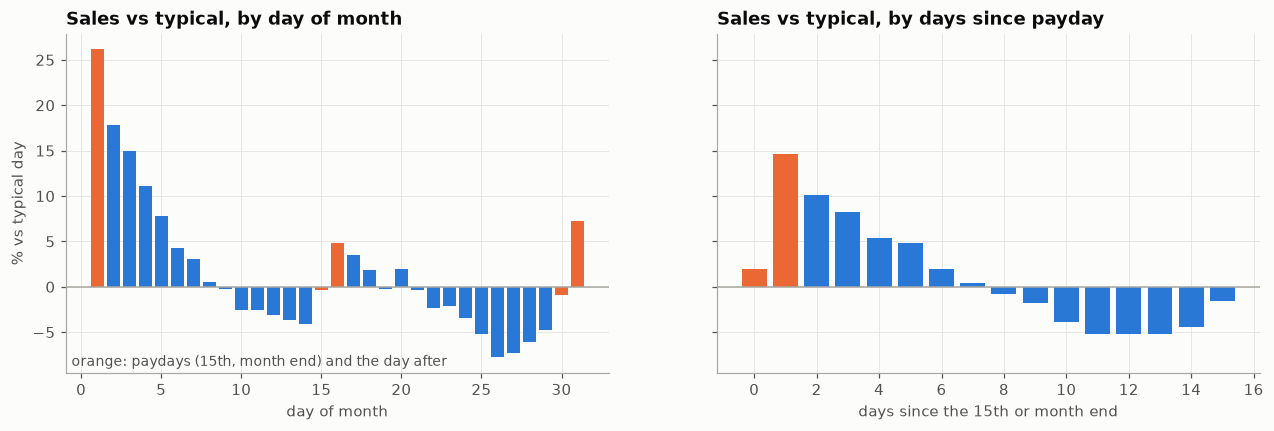

days since payday, % vs typical day:
0     1.9100
1    14.6000
2    10.1600
3     8.2300
4     5.3500
5     4.8600
6     1.9700
7     0.3700
8    -0.7900
9    -1.8100
10   -3.8800
11   -5.1600
12   -5.2200
13   -5.2000
14   -4.4700
15   -1.6000


In [7]:
trend29 = log_total.rolling(29, center=True, min_periods=15).median()
resid = log_total - trend29
resid = resid - resid.groupby(resid.index.day_of_week).transform("median")  # weekday removed

keep = ~((resid.index.month == 12) | ((resid.index.month == 1) & (resid.index.day <= 2)))
r = resid[keep].dropna()
by_dom = (np.exp(r.groupby(r.index.day).mean()) - 1) * 100
dsp = pd.Series(features.days_since_payday(r.index), index=r.index)
by_dsp = (np.exp(r.groupby(dsp).mean()) - 1) * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
ax = axes[0]
ax.bar(by_dom.index, by_dom.to_numpy(), color=[ORANGE if d in (15, 30, 31, 1, 16) else BLUE for d in by_dom.index], width=0.8)
ax.axhline(0, color=NEUTRAL, lw=1)
ax.set(title="Sales vs typical, by day of month", xlabel="day of month", ylabel="% vs typical day")
ax.text(0.01, 0.02, "orange: paydays (15th, month end) and the day after", transform=ax.transAxes, color=INK2, fontsize=9)
ax = axes[1]
ax.bar(by_dsp.index, by_dsp.to_numpy(), color=[ORANGE if d <= 1 else BLUE for d in by_dsp.index], width=0.8)
ax.axhline(0, color=NEUTRAL, lw=1)
ax.set(title="Sales vs typical, by days since payday", xlabel="days since the 15th or month end")
save(fig, "paydays")
plt.show()
print("days since payday, % vs typical day:")
print(by_dsp.round(2).to_string())
SUMMARY["payday day 0 / day 1 effect %"] = (round(float(by_dsp.loc[0]), 1), round(float(by_dsp.loc[1]), 1))

The payday effect is real, but it isn't the symmetric "15th and month end" story I expected. It's mostly a start-of-month effect: the 1st is about +26% above typical, then it decays day by day (+18, +15, +11, +8%...) to about −5 to −8% around the 25th–28th. The middle of the month barely shows: the 15th is flat and the 16th is only about +5%. The last day is about +7%.

The days-since-payday chart mixes the strong month start with the weak mid-month, so its "day 1 = +14.6%" is an average of two different effects. For features I'll use the day of the month directly (or days since the 1st), plus separate flags for the 15th/16th and the month end. Days since payday on its own would blur them together.

The weekly-differenced ACF further down shows a wave that peaks at lags of about 16, 31, 46 and 60 days, a cycle of roughly half a month. So the mid-month payday does leave a mark, even though the 1st is much stronger than the 16th.

## 5 · Holidays and events

In [8]:
# Structure of the holidays file
print("rows by type and locale:")
print(hol.groupby(["type", "locale"]).size().unstack(fill_value=0), "\n")

per_date = hol.groupby("date").size()
multi = per_date[per_date > 1]
print(f"{len(multi)} dates have more than one row, e.g.:")
print(hol[hol["date"].isin(multi.index[:4])].to_string(index=False))

rows by type and locale:
locale      Local  National  Regional
type                                 
Additional     11        40         0
Bridge          0         5         0
Event           0        56         0
Holiday       137        60        24
Transfer        4         8         0
Work Day        0         5         0 

31 dates have more than one row, e.g.:
      date       type   locale   locale_name                   description  transferred
2012-06-25    Holiday Regional      Imbabura Provincializacion de Imbabura        False
2012-06-25    Holiday    Local     Latacunga    Cantonizacion de Latacunga        False
2012-06-25    Holiday    Local       Machala          Fundacion de Machala        False
2012-07-03    Holiday    Local Santo Domingo    Fundacion de Santo Domingo        False
2012-07-03    Holiday    Local     El Carmen    Cantonizacion de El Carmen        False
2012-12-22    Holiday    Local       Salinas      Cantonizacion de Salinas        False
2012-12-22 Add

The holidays file has 350 rows on 312 dates, and 31 dates have more than one row. Sometimes that's several cities on the same day (June 25 has a regional and two local holidays). Sometimes it's a national Additional day on top of a Bridge (Dec 24). That confirms the Phase 0 warning: I have to collapse it per date and locale before merging, or train rows get duplicated.

In [9]:
# Transferred holidays: the official date (transferred=True) and the day actually celebrated (type=Transfer)
cols = ["date", "type", "locale", "locale_name", "description", "transferred"]
print(hol.loc[hol["transferred"] | (hol["type"] == "Transfer"), cols].sort_values("date").to_string(index=False))
print("\nBridge and Work Day rows:")
print(hol.loc[hol["type"].isin(["Bridge", "Work Day"]), cols].sort_values("date").to_string(index=False))

      date     type   locale locale_name                            description  transferred
2012-10-09  Holiday National     Ecuador             Independencia de Guayaquil         True
2012-10-12 Transfer National     Ecuador    Traslado Independencia de Guayaquil        False
2013-10-09  Holiday National     Ecuador             Independencia de Guayaquil         True
2013-10-11 Transfer National     Ecuador    Traslado Independencia de Guayaquil        False
2014-10-09  Holiday National     Ecuador             Independencia de Guayaquil         True
2014-10-10 Transfer National     Ecuador    Traslado Independencia de Guayaquil        False
2016-05-24  Holiday National     Ecuador                   Batalla de Pichincha         True
2016-05-27 Transfer National     Ecuador          Traslado Batalla de Pichincha        False
2016-07-24 Transfer    Local   Guayaquil        Traslado Fundacion de Guayaquil        False
2016-07-25  Holiday    Local   Guayaquil                 Fundacion de 

The transfer pairs line up: the official date has transferred=True and the day actually celebrated is a Transfer row (Guayaquil's independence moved from Oct 9 to Oct 10–12, Batalla de Pichincha from May 24 to May 26–27). Local holidays can be transferred too (Guayaquil 2016, Cuenca, Ibarra and Quito 2017).

Two transfers matter directly. On 2017-01-01 New Year is "transferred" to Jan 2, yet stores were still closed on Jan 1 2017 (only 12k in sales). So the Jan 1 closure has to be a calendar rule, not something read from the holidays file. And on 2017-08-10 the independence holiday moved to Aug 11, which falls inside backtest fold 4.

Work Day rows are Saturdays that became working days to make up for a Bridge. They should count as normal days, which is what excluding them here does.

left out of the chart so the rest stays readable (|effect| > 50%):
   type              label  n  effect  effect_%
Holiday Primer dia del ano  4 -4.2000  -98.5000 



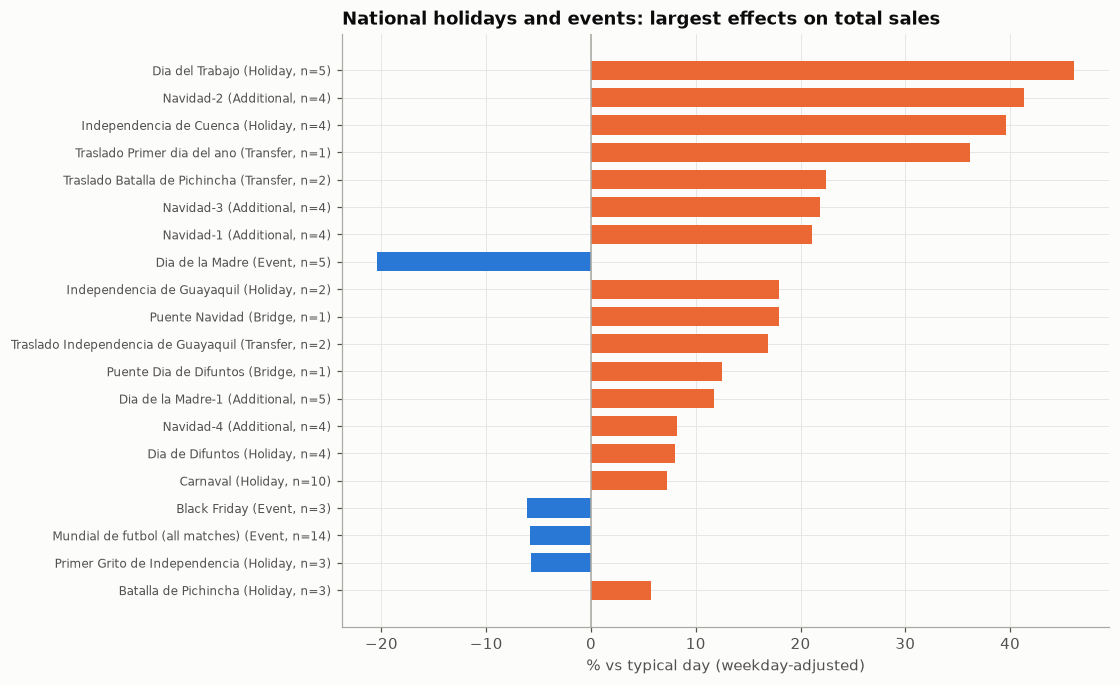

      type                                  label  n  effect_%
   Holiday                     Primer dia del ano  4  -98.5000
     Event                        Dia de la Madre  5  -20.4000
     Event                           Black Friday  3   -6.1000
     Event        Mundial de futbol (all matches) 14   -5.8000
   Holiday          Primer Grito de Independencia  3   -5.7000
Additional                              Navidad+1  4   -1.5000
    Bridge              Puente Primer dia del ano  1    0.7000
   Holiday                          Viernes Santo  5    1.0000
     Event                           Cyber Monday  3    3.8000
     Event            Terremoto Manabi (all days) 31    4.3000
Additional                   Primer dia del ano-1  4    5.5000
  Transfer Traslado Primer Grito de Independencia  2    5.6000
   Holiday                   Batalla de Pichincha  3    5.7000
   Holiday                               Carnaval 10    7.3000
   Holiday                        Dia de Difuntos  4   

In [10]:
# Effect of national holidays and events on total sales (same weekday-adjusted residual as for paydays)
nat = hol[(hol["locale"] == "National") & ~hol["transferred"] & (hol["type"] != "Work Day")
          & hol["date"].between(cv.TRAIN_START, cv.TRAIN_END)].copy()
nat["resid"] = nat["date"].map(resid)
# Group day-by-day event series into one label each (the earthquake has a row per day, the World Cup per match)
nat["label"] = nat["description"]
nat.loc[nat["description"].str.contains("Terremoto", case=False), "label"] = "Terremoto Manabi (all days)"
nat.loc[nat["description"].str.contains("Mundial", case=False), "label"] = "Mundial de futbol (all matches)"
eff = (nat.dropna(subset=["resid"]).groupby(["type", "label"])
          .agg(n=("date", "size"), effect=("resid", "mean")).reset_index())
eff["effect_%"] = (np.exp(eff["effect"]) - 1) * 100
extreme = eff[eff["effect_%"].abs() > 50]
print("left out of the chart so the rest stays readable (|effect| > 50%):")
print(extreme.round(1).to_string(index=False), "\n")
plot_eff = eff.drop(extreme.index)
top = plot_eff.reindex(plot_eff["effect_%"].abs().sort_values(ascending=False).index).head(20).iloc[::-1]

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh([f"{d} ({t}, n={n})" for d, t, n in zip(top["label"], top["type"], top["n"])],
        top["effect_%"], color=[ORANGE if v > 0 else BLUE for v in top["effect_%"]], height=0.7)
ax.axvline(0, color=NEUTRAL, lw=1)
ax.tick_params(axis="y", labelsize=8)
ax.set(title="National holidays and events: largest effects on total sales", xlabel="% vs typical day (weekday-adjusted)")
save(fig, "national_holidays")
plt.show()
print(eff.drop(columns="effect").sort_values("effect_%").round(1).to_string(index=False))

Jan 1 is −98.5%, as expected, and is left out of the chart.

Many of the other numbers are confounded, so I can't take them at face value. Dia del Trabajo (+46%) is May 1, i.e. the 1st of the month, which is already about +26% from the month-start effect. Independencia de Cuenca (+40%) and Dia de Difuntos (+8%) are Nov 2–3, also at the start of a month. Navidad-1 to -4 (+8% to +41%) sit inside the December ramp, which a 29-day median only partly removes. "Traslado Primer dia del ano" (+36%) is Jan 2 2017, the rebound after the closure. Dia de la Madre (−20%) is always a Sunday, so it's being compared with the strongest weekday; the day before is +12%.

The genuinely small ones: Carnaval (+7%), the earthquake days (+4%), Black Friday and the World Cup matches (about −6%).

This method takes away the trend and the weekday pattern but nothing else, so overlapping effects get credited to whichever one I happen to be looking at. Separating them needs all the effects in one regression at once, which is what Phase 4 is for.

In [11]:
# Local and regional holidays: do they move sales in the matching stores?
# Store-level residual, same recipe as for the total
log_st = np.log(ST.where(ST > 0))
res_st = log_st - log_st.rolling(29, center=True, min_periods=15).median()
res_st = res_st - res_st.groupby(res_st.index.day_of_week).transform("median")

city = stores.set_index("store_nbr")["city"]
state = stores.set_index("store_nbr")["state"]
rows = []
for h in hol[(hol["locale"] != "National") & ~hol["transferred"] & (hol["type"] != "Work Day")
             & hol["date"].between(cv.TRAIN_START, cv.TRAIN_END)].itertuples():
    where = city if h.locale == "Local" else state
    match = where.index[where == h.locale_name]
    if len(match) == 0 or h.date not in res_st.index:
        continue
    day = res_st.loc[h.date]
    rows.append({"locale": h.locale, "type": h.type, "description": h.description,
                 "matched": day[match].mean(), "others": day.drop(match).mean()})
loc_eff = pd.DataFrame(rows).dropna()
loc_eff["diff_%"] = (np.exp(loc_eff["matched"] - loc_eff["others"]) - 1) * 100
print("matched stores vs other stores on the same day, % difference:")
print(loc_eff.groupby(["locale", "type"])["diff_%"].agg(["count", "mean", "median"]).round(1))

no_store = sorted(set(hol.loc[hol["locale"] == "Local", "locale_name"]) - set(stores["city"]))
print("\nlocal holidays in cities with no store:", no_store)
print("\nholiday rows in the test period:")
in_test = hol[hol["date"].between(cv.TEST_START, cv.TEST_END)]
print(in_test.to_string(index=False))
for h in in_test.itertuples():
    where = city if h.locale == "Local" else state
    print(f"stores affected by {h.description}:", list(where.index[where == h.locale_name]) if h.locale != "National" else "all")
SUMMARY["local holiday effect, matched stores %"] = round(float(loc_eff.loc[loc_eff["locale"] == "Local", "diff_%"].mean()), 1)

matched stores vs other stores on the same day, % difference:
                     count    mean  median
locale   type                             
Local    Additional      9 -6.9000 -5.6000
         Holiday        97 -2.4000 -3.9000
         Transfer        2 -6.7000 -6.7000
Regional Holiday        18 -0.1000 -3.1000

local holidays in cities with no store: []

holiday rows in the test period:
      date    type locale locale_name         description  transferred
2017-08-24 Holiday  Local      Ambato Fundacion de Ambato        False
stores affected by Fundacion de Ambato: [23, 50]


Local holidays slightly lower sales in the matching stores compared with other stores on the same day: mean −2.4%, median −3.9%, over 97 events. Regional holidays do almost nothing on average (mean −0.1%, median −3.1%, 18 events). These effects are small next to the weekly and monthly ones, so the local/regional matching is worth doing, but I don't expect much from it.

Every local holiday city has a store, so all of them can be matched. There's exactly one holiday in the test period: Fundacion de Ambato on 2017-08-24, which affects stores 23 and 50 only.

## 6 · The April 2016 earthquake

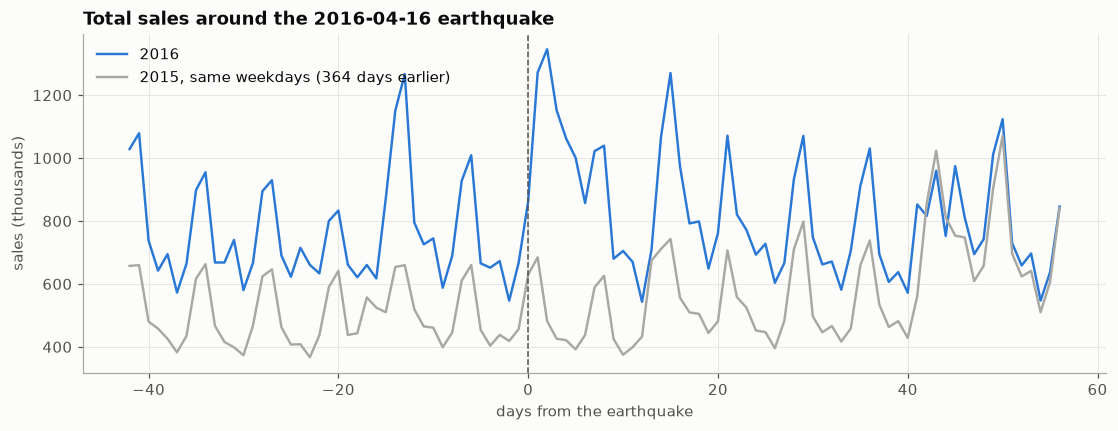

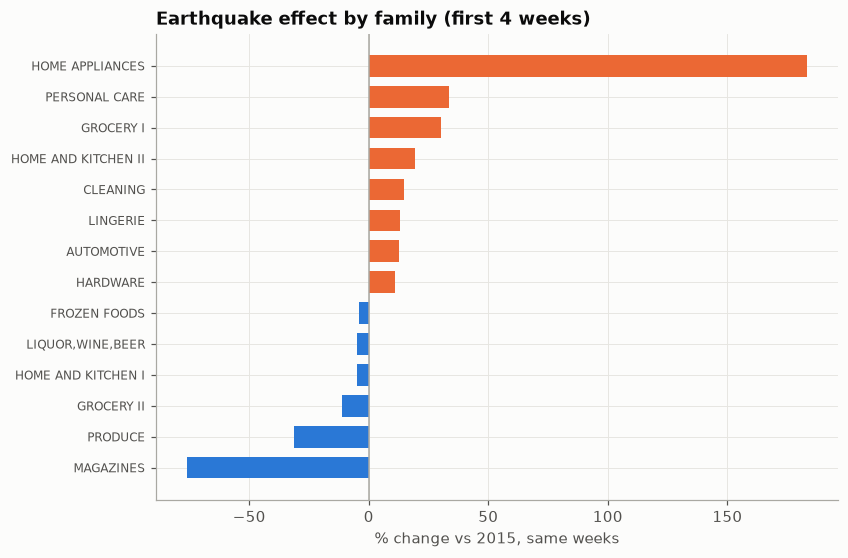

total sales, first 4 weeks after vs before, relative to 2015: +11.2%
stores in Manabi (the epicentre province): [52, 53, 54]


In [12]:
QUAKE = pd.Timestamp("2016-04-16")
offs = np.arange(-42, 57)
a = total.reindex(QUAKE + pd.to_timedelta(offs, "D")).to_numpy()
b = total.reindex(QUAKE - pd.Timedelta(days=364) + pd.to_timedelta(offs, "D")).to_numpy()   # same weekdays, 2015

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(offs, a / 1e3, color=BLUE, label="2016")
ax.plot(offs, b / 1e3, color=NEUTRAL, label="2015, same weekdays (364 days earlier)")
ax.axvline(0, color=INK2, lw=1, ls="--")
ax.set(title="Total sales around the 2016-04-16 earthquake", xlabel="days from the earthquake", ylabel="sales (thousands)")
ax.legend(loc="upper left")
save(fig, "earthquake_total")
plt.show()

# Family-level: (4 weeks after vs 6 weeks before) in 2016, minus the same comparison in 2015
fam_daily = train.groupby(["date", "family"])["sales"].sum().unstack().reindex(CAL)
def lr(t0):
    pre = fam_daily.loc[t0 - pd.Timedelta(days=42): t0 - pd.Timedelta(days=1)].mean()
    post = fam_daily.loc[t0 + pd.Timedelta(days=1): t0 + pd.Timedelta(days=28)].mean()
    return np.log(post / pre)
did = (lr(QUAKE) - lr(QUAKE - pd.Timedelta(days=364))).replace([np.inf, -np.inf], np.nan).dropna()
did_pct = ((np.exp(did) - 1) * 100).sort_values()
show = pd.concat([did_pct.head(6), did_pct.tail(8)])

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(show.index, show.to_numpy(), color=[ORANGE if v > 0 else BLUE for v in show], height=0.7)
ax.axvline(0, color=NEUTRAL, lw=1)
ax.tick_params(axis="y", labelsize=8)
ax.set(title="Earthquake effect by family (first 4 weeks)", xlabel="% change vs 2015, same weeks")
save(fig, "earthquake_families")
plt.show()

tot_did = float(np.log(total[QUAKE + pd.Timedelta(days=1): QUAKE + pd.Timedelta(days=28)].mean()
                       / total[QUAKE - pd.Timedelta(days=42): QUAKE - pd.Timedelta(days=1)].mean())
                - np.log(total[QUAKE - pd.Timedelta(days=363): QUAKE - pd.Timedelta(days=336)].mean()
                         / total[QUAKE - pd.Timedelta(days=406): QUAKE - pd.Timedelta(days=365)].mean()))
print(f"total sales, first 4 weeks after vs before, relative to 2015: {np.exp(tot_did) * 100 - 100:+.1f}%")
print("stores in Manabi (the epicentre province):", list(stores.loc[stores["state"] == "Manabi", "store_nbr"]))
SUMMARY["earthquake: total, 4 weeks after, % vs 2015"] = round(float(np.exp(tot_did)) * 100 - 100, 1)

Total sales ran about 11% above normal in the four weeks after the earthquake, compared with the same weeks of 2015. The total plot shows a sharp jump in the first days that then fades over about a month.

The family chart is less trustworthy than it looks. The 2015 comparison window (March–May 2015) falls inside the data gap for PRODUCE, MAGAZINES and the other late families, so their numbers (PRODUCE −30%, MAGAZINES −75%) compare against missing data. HOME APPLIANCES +180% is a tiny family. The believable part is GROCERY I, PERSONAL CARE and CLEANING going up, which fits relief buying. The extreme rows in section 8 support that too.

Decision: flag the period from 2016-04-16 to about mid-May 2016 as an earthquake period (or leave it out of training) so it doesn't teach the model a fake pattern. The stores in Manabí are 52, 53 and 54.

## 7 · Families and stores

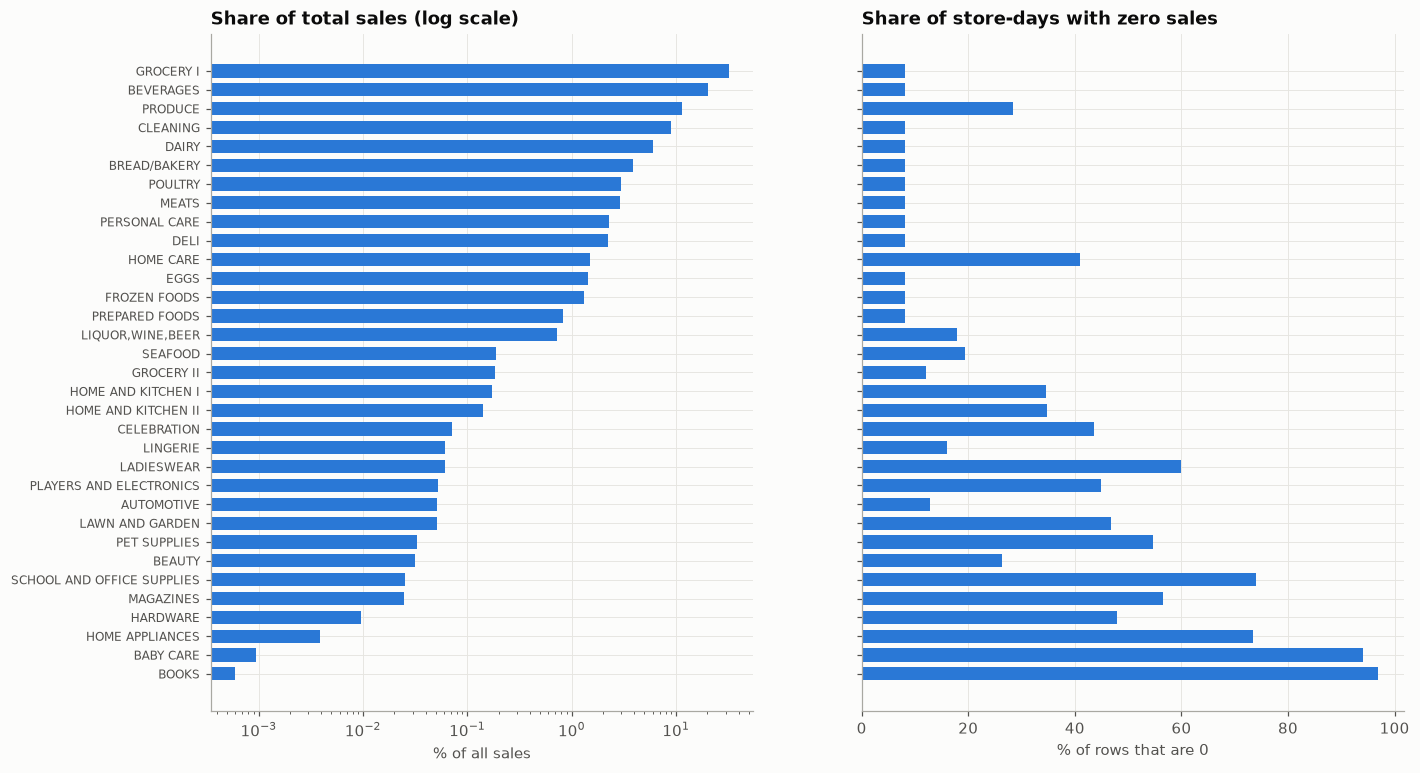

                            share_%  zero_share
family                                         
GROCERY I                   31.9900      0.0810
BEVERAGES                   20.2070      0.0810
PRODUCE                     11.4290      0.2840
CLEANING                     9.0830      0.0810
DAIRY                        6.0060      0.0810
BREAD/BAKERY                 3.9240      0.0810
POULTRY                      2.9690      0.0810
MEATS                        2.8950      0.0810
PERSONAL CARE                2.2910      0.0810
DELI                         2.2460      0.0810
HOME CARE                    1.4920      0.4090
EGGS                         1.4520      0.0810
FROZEN FOODS                 1.3110      0.0810
PREPARED FOODS               0.8200      0.0810
LIQUOR,WINE,BEER             0.7220      0.1790
SEAFOOD                      0.1880      0.1940
GROCERY II                   0.1830      0.1210
HOME AND KITCHEN I           0.1730      0.3460
HOME AND KITCHEN II          0.1420     

In [13]:
fam = (train.assign(zero=train["sales"].eq(0))
            .groupby("family").agg(total=("sales", "sum"), zero_share=("zero", "mean")))
fam["share_%"] = fam["total"] / fam["total"].sum() * 100
fam = fam.sort_values("share_%")

fig, axes = plt.subplots(1, 2, figsize=(14, 8), sharey=True)
axes[0].barh(fam.index, fam["share_%"], color=BLUE, height=0.7)
axes[0].set_xscale("log")
axes[0].set(title="Share of total sales (log scale)", xlabel="% of all sales")
axes[1].barh(fam.index, fam["zero_share"] * 100, color=BLUE, height=0.7)
axes[1].set(title="Share of store-days with zero sales", xlabel="% of rows that are 0")
axes[0].tick_params(axis="y", labelsize=8)
save(fig, "families")
plt.show()
print(fam[["share_%", "zero_share"]].iloc[::-1].round(3).to_string())
SUMMARY["top 3 families, % of sales"] = round(float(fam["share_%"].nlargest(3).sum()), 1)

Sales are concentrated: GROCERY I (32%), BEVERAGES (20%) and PRODUCE (11%) make 64%, and CLEANING adds 9%. Eighteen families are each under 0.2% of sales. RMSLE weights every row equally whatever its size, though, so the small families count just as much in the metric as GROCERY I.

The zero share column hides a useful detail: most families sit at exactly 8.1%. I checked where that comes from. The days before the 8 late stores opened (6,684 store-days), the 6 long closures (398) and the Jan 1sts (270) add up to 8.08% of all rows. So 8.1% of the data is "store not open" zeros that every family shares. Anything above 8.1% is a family-specific zero: BOOKS 97%, BABY CARE 94%, SCHOOL AND OFFICE SUPPLIES 74%, HOME APPLIANCES 74%.

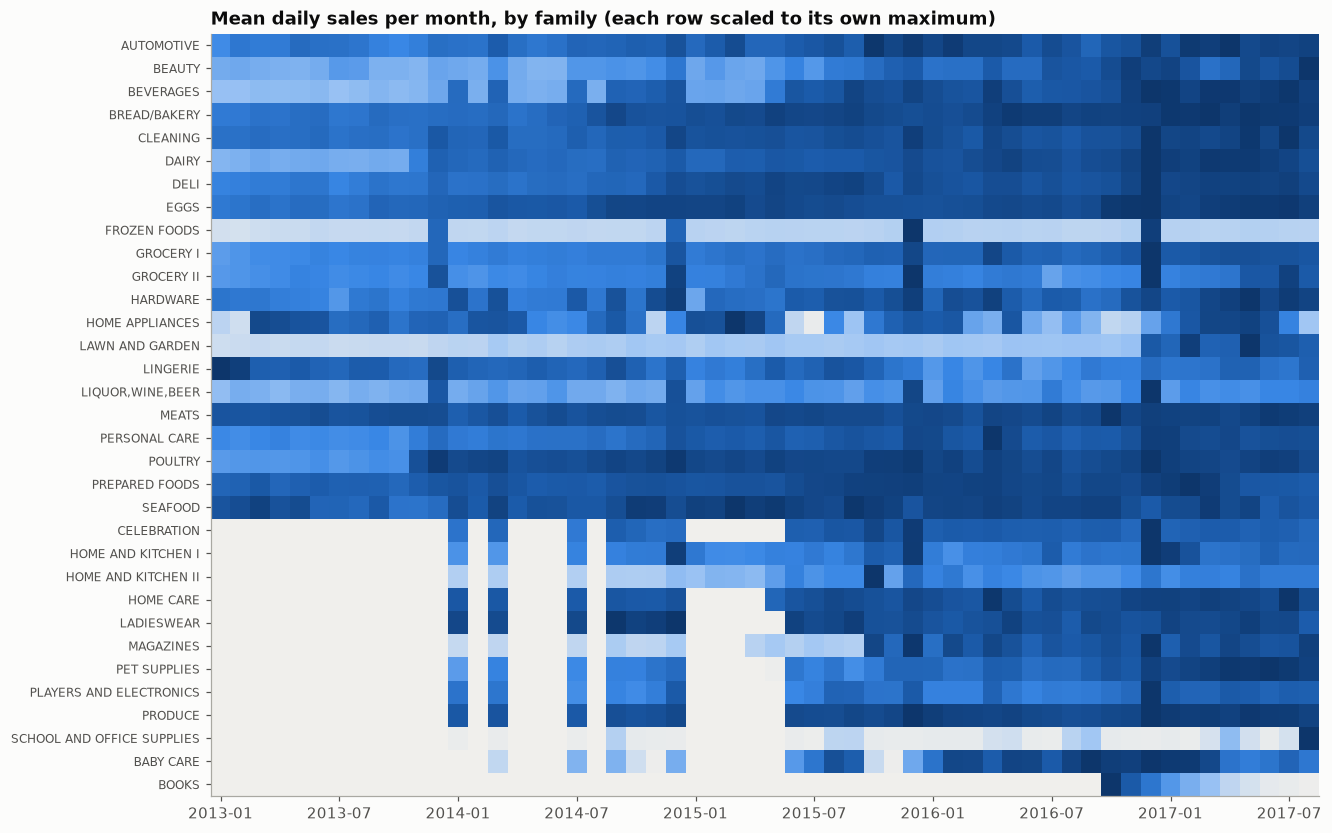

families that start after January 2013 (first month above 1% of their peak):
family
HOME AND KITCHEN I            2014-01
CELEBRATION                   2014-01
HOME CARE                     2014-01
HOME AND KITCHEN II           2014-01
LADIESWEAR                    2014-01
MAGAZINES                     2014-01
PLAYERS AND ELECTRONICS       2014-01
PET SUPPLIES                  2014-01
PRODUCE                       2014-01
SCHOOL AND OFFICE SUPPLIES    2014-01
BABY CARE                     2014-03
BOOKS                         2016-10


In [14]:
# When does each family start selling? Monthly sales per family, each row scaled to its own max
# Mean daily sales per month (not the sum), so the half month of August 2017 isn't artificially low
fam_daily_m = train.groupby(["date", "family"])["sales"].sum().unstack()
fm = fam_daily_m.groupby(fam_daily_m.index.to_period("M")).mean().T
# First month above 1% of the family's peak month, so one stray sale doesn't count as a start
first_month = fm.gt(0.01 * fm.max(axis=1).to_numpy()[:, None]).idxmax(axis=1)
fm = fm.loc[first_month.sort_values(kind="stable").index]
fm_norm = fm.div(fm.max(axis=1).replace(0, np.nan), axis=0)

fig, ax = plt.subplots(figsize=(13, 9))
ax.imshow(fm_norm.to_numpy(dtype="float64"), cmap=SEQ, aspect="auto", vmin=0, vmax=1, interpolation="nearest")
ax.set_yticks(range(len(fm_norm)), fm_norm.index, fontsize=8)
ticks = range(0, fm_norm.shape[1], 6)
ax.set_xticks(list(ticks), [str(fm_norm.columns[i]) for i in ticks])
ax.grid(False)
ax.set_title("Mean daily sales per month, by family (each row scaled to its own maximum)")
save(fig, "family_by_month")
plt.show()
late_fam = first_month[first_month > pd.Period("2013-01", "M")]
print("families that start after January 2013 (first month above 1% of their peak):")
print(late_fam.sort_values().to_string())

This is the most important plot in the notebook. Ten families have no sales recorded anywhere in 2013: CELEBRATION, HOME AND KITCHEN I and II, HOME CARE, LADIESWEAR, MAGAZINES, PET SUPPLIES, PLAYERS AND ELECTRONICS, PRODUCE and SCHOOL AND OFFICE SUPPLIES. BABY CARE starts in March 2014. In 2014 these families appear in some months and vanish in others. They vanish again from January to about May 2015, and only run continuously from around June 2015.

Grocery stores don't stop selling produce for months at a time, so these zeros are missing records, not real demand. This explains the humps in the total-sales plot, the fake 2014 "growth", the chaotic 2014–2015 monthly pattern and the block-shaped remainder in the MSTL further down.

BOOKS starting in October 2016 looks like a real product launch, not a gap. FROZEN FOODS is light except for a few dark Decembers, which is just a very strong Christmas peak.

stores whose first sale is more than 30 days after 2013-01-01:
store_nbr
36    2013-05-09
53    2014-05-29
20    2015-02-13
29    2015-03-20
21    2015-07-24
42    2015-08-21
22    2015-10-09
52    2017-04-20 

stores with a closure of 7+ days after opening:
           zero_days        from          to
store_nbr                                   
18               110  2016-08-15  2016-12-02
24               101  2014-04-14  2014-07-23
25                66  2016-08-22  2016-10-26
12                60  2015-03-30  2015-05-28
14                38  2014-08-04  2014-09-10
30                23  2013-07-08  2013-07-30


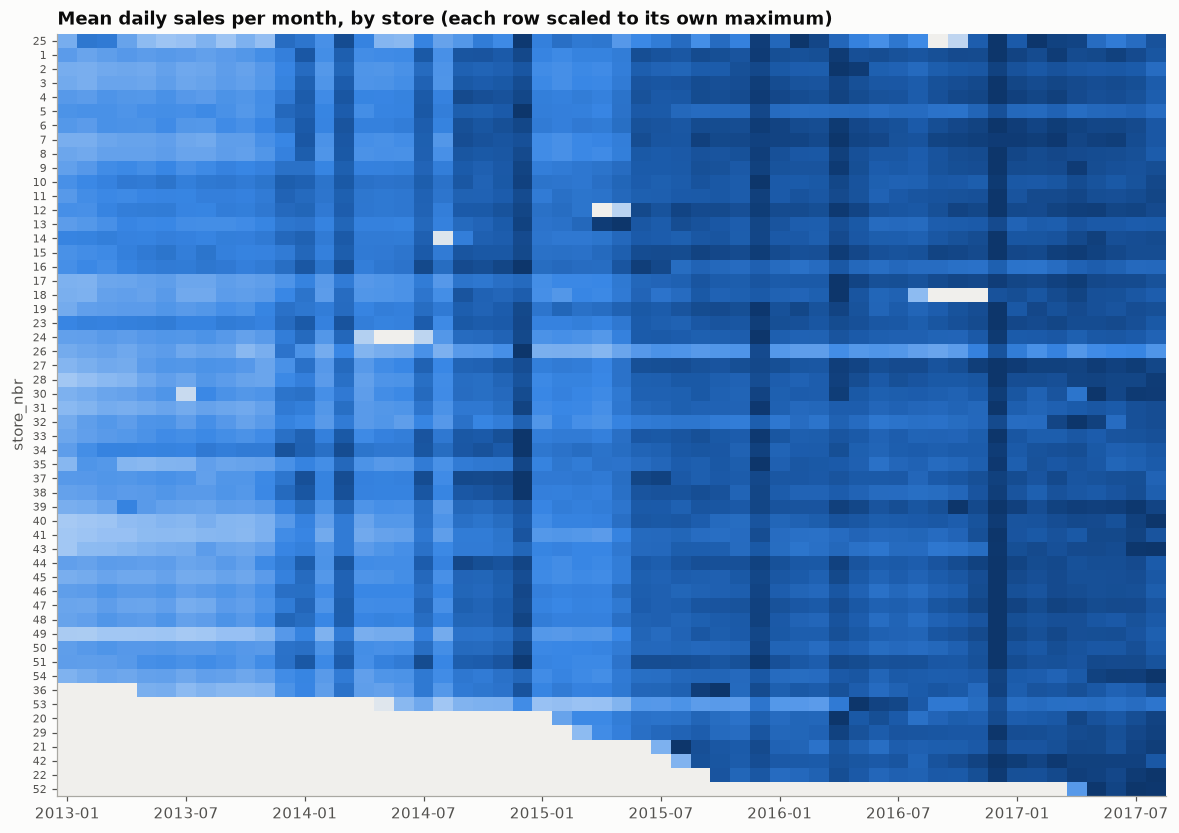

In [15]:
# When does each store open, and does it close for long stretches?
first_sale = ST.gt(0).idxmax()
late_stores = first_sale[first_sale > cv.TRAIN_START + pd.Timedelta(days=30)].sort_values()
print("stores whose first sale is more than 30 days after 2013-01-01:")
print(late_stores.dt.date.to_string(), "\n")

def longest_zero_run(s):
    """Longest run of zero-sales days after the first sale (NaN days don't break or extend a run)."""
    s = s[s.index >= s.gt(0).idxmax()].dropna()
    z = s.eq(0)
    if not z.any():
        return 0, None, None
    runs = (~z).cumsum()[z]
    sizes = runs.value_counts()
    rid = sizes.idxmax()
    days = runs.index[runs == rid]
    return int(sizes.max()), days.min().date(), days.max().date()

closures = pd.DataFrame([(sn, *longest_zero_run(ST[sn])) for sn in ST.columns],
                        columns=["store_nbr", "zero_days", "from", "to"]).set_index("store_nbr")
print("stores with a closure of 7+ days after opening:")
print(closures[closures["zero_days"] >= 7].sort_values("zero_days", ascending=False).to_string())

st_m = ST.resample("MS").mean()   # mean daily sales per month
st_norm = st_m.div(st_m.max()).T.loc[first_sale.sort_values(kind="stable").index]
fig, ax = plt.subplots(figsize=(13, 9))
ax.imshow(st_norm.to_numpy(dtype="float64"), cmap=SEQ, aspect="auto", vmin=0, vmax=1, interpolation="nearest")
ax.set_yticks(range(len(st_norm)), st_norm.index, fontsize=7)
ticks = range(0, st_norm.shape[1], 6)
ax.set_xticks(list(ticks), [st_norm.columns[i].strftime("%Y-%m") for i in ticks])
ax.grid(False)
ax.set(title="Mean daily sales per month, by store (each row scaled to its own maximum)", ylabel="store_nbr")
save(fig, "store_by_month")
plt.show()
SUMMARY["stores opening after Feb 2013"] = len(late_stores)

Eight stores open late: 36 (May 2013), 53 (May 2014), 20, 29, 21, 42 and 22 (all during 2015), and 52 on 2017-04-20. Store 52 has less than four months of history before the test period, so lag features exist for it but long-memory features like a 364-day lag don't. Six stores have long closures after opening: store 18 for 110 days (Aug–Dec 2016), store 24 for 101 days (2014), store 25 for 66 days (Aug–Oct 2016), store 12 for 60 days (2015), store 14 for 38 days and store 30 for 23 days.

During a closure every family of that store shows zero. If I compute lags or rolling means across a closure, the model sees a collapse and then a "recovery" that has nothing to do with demand. So closed store-days should be treated as missing, not as zero sales, both in the training rows and in the lag windows.

In [16]:
# Series that are always zero, and series that have gone quiet
zero_all = W.fillna(0).eq(0).all()
print("series with zero sales on every day:", int(zero_all.sum()))
print(zero_all[zero_all].index.get_level_values("family").value_counts().to_string(), "\n")

# Fold-aware check: if a series sold nothing in the last N days before a window, does it stay at zero for the 16 days?
rows = []
for f in cv.FOLDS:
    fut_zero = W.loc[f.valid_start:f.valid_end].eq(0).all()
    for n in (14, 28, 56):
        hist_zero = W.loc[f.train_end - pd.Timedelta(days=n - 1): f.train_end].fillna(0).eq(0).all()
        rows.append({"fold": f.fold, "lookback_days": n, "series_zero_in_lookback": int(hist_zero.sum()),
                     "stay_zero_all_16_days": int((hist_zero & fut_zero).sum())})
zr = pd.DataFrame(rows)
zr["share_staying_zero"] = zr["stay_zero_all_16_days"] / zr["series_zero_in_lookback"]
print(zr.pivot(index="lookback_days", columns="fold", values=["series_zero_in_lookback", "share_staying_zero"]).round(3))
SUMMARY["series always zero"] = int(zero_all.sum())
SUMMARY["series zero in last 28 days of train"] = int(W.loc[cv.TRAIN_END - pd.Timedelta(days=27):].eq(0).all().sum())

series with zero sales on every day: 53
family
BOOKS              28
BABY CARE          12
LADIESWEAR         10
LAWN AND GARDEN     3 

              series_zero_in_lookback                            share_staying_zero                     
fold                                1        2        3        4                  1      2      3      4
lookback_days                                                                                           
14                           123.0000 128.0000 120.0000 121.0000             0.9350 0.8440 0.8920 0.9170
28                           103.0000 115.0000 109.0000 108.0000             0.9710 0.8870 0.9450 0.9260
56                            88.0000  93.0000  93.0000  99.0000             1.0000 0.9250 0.9680 0.9490


53 series sold nothing on any day: 28 BOOKS, 12 BABY CARE, 10 LADIESWEAR and 3 LAWN AND GARDEN. 114 series sold nothing in the last 28 days of training, so about 60 more have gone quiet recently.

The fold check says a simple zero rule is reliable. Of the series with no sales in the 56 days before a window, 92.5–100% stay at zero for all 16 days. A 28-day lookback gives 89–97%, and 14 days gives 84–94%. A longer lookback flags fewer series but is right more often.

This table looks at the validation windows, so picking the lookback here would be tuning on the folds. I'll add the zero rule as a model component in Phase 3 and score each lookback through the backtest like any other choice.

## 8 · The target's distribution, and why log1p + RMSLE

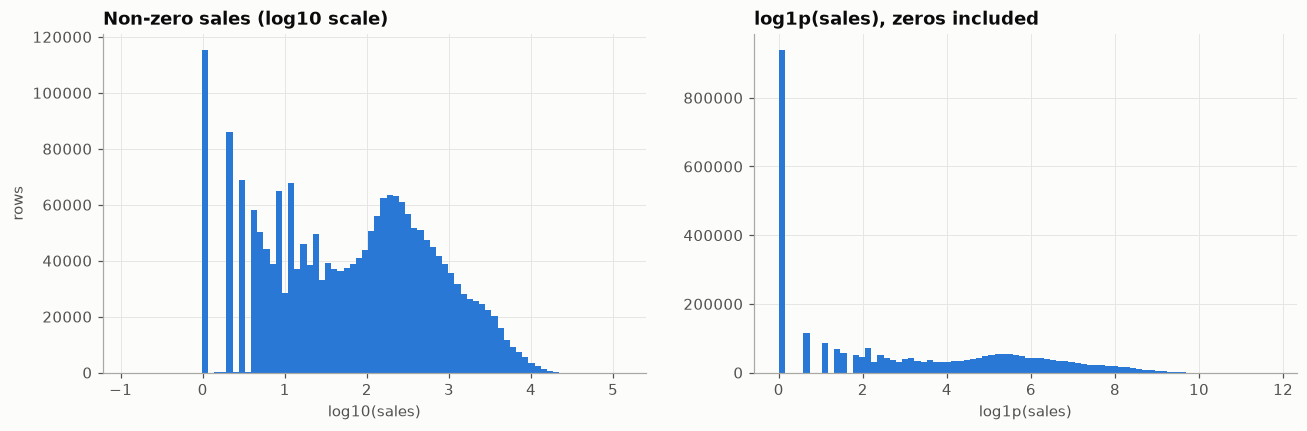

zeros: 31.3%  |  skew raw: 7.4  |  skew log1p: 0.41
count   3,000,888.0000
mean          357.8000
std         1,102.0000
min             0.0000
50%            11.0000
90%           867.0000
99%         5,507.0000
99.9%      12,076.2000
max       124,717.0000


In [17]:
s = train["sales"]
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(np.log10(s[s > 0]), bins=80, color=BLUE)
axes[0].set(title="Non-zero sales (log10 scale)", xlabel="log10(sales)", ylabel="rows")
axes[1].hist(np.log1p(s), bins=80, color=BLUE)
axes[1].set(title="log1p(sales), zeros included", xlabel="log1p(sales)")
save(fig, "sales_distribution")
plt.show()
print(f"zeros: {s.eq(0).mean():.1%}  |  skew raw: {s.skew():.1f}  |  skew log1p: {np.log1p(s).skew():.2f}")
print(s.describe(percentiles=[0.5, 0.9, 0.99, 0.999]).round(1).to_string())

31.3% of rows are zero, the median sale is 11 and the mean is 358. The 99th percentile is 5,507 and the maximum 124,717. Raw skewness is 7.4; log1p brings it down to 0.41.

The log1p histogram still isn't one bell: it's a spike of zeros (about a third of the data) next to a broad hump. Part of the zero spike is the 8.1% of closed-store days. The non-zero histogram has tall spikes at 1, 2, 3… because most families are sold in whole units, while PRODUCE, MEATS, POULTRY and DELI are sold by weight and fill in the gaps. A linear model on log1p will struggle with the zero spike; trees can split it off.

In [18]:
# Squared error vs squared log error on four cases
ex = pd.DataFrame({"y": [10.0, 10_000.0, 0.0, 0.0], "y_pred": [20.0, 10_010.0, 5.0, 1.0]})
ex["squared_error"] = (ex["y_pred"] - ex["y"]) ** 2
ex["squared_log_error"] = (np.log1p(ex["y_pred"]) - np.log1p(ex["y"])) ** 2
ex["abs_pct_error"] = np.where(ex["y"] > 0, (ex["y_pred"] - ex["y"]).abs() / ex["y"], np.inf)
print(ex.to_string(index=False))

          y      y_pred  squared_error  squared_log_error  abs_pct_error
    10.0000     20.0000       100.0000             0.4181         1.0000
10,000.0000 10,010.0000       100.0000             0.0000         0.0010
     0.0000      5.0000        25.0000             3.2104            inf
     0.0000      1.0000         1.0000             0.4805            inf


This is the reason for RMSLE in four rows. Being off by 10 units costs the same squared error (100) on a sale of 10 and on a sale of 10,000. In log terms, the first is a big mistake (0.42) and the second almost none (0.00001). RMSLE scores relative errors, so a store that sells 10 matters as much as one that sells 10,000.

The last two rows are the zero problem. Predicting 5 when the truth is 0 costs 3.2, more than doubling a sale. Predicting 1 for a zero costs 0.48. Percentage error is undefined when the truth is zero, which is why MAPE can't be used here. Predicting exact zeros for dead series is worth a lot.

In [19]:
# The largest sales rows, and the context of the maximum
print(train.nlargest(10, "sales")[["date", "store_nbr", "family", "sales", "onpromotion"]].to_string(index=False))
mx = train.loc[train["sales"].idxmax()]
ctx = W[(mx["store_nbr"], mx["family"])].loc[mx["date"] - pd.Timedelta(days=10): mx["date"] + pd.Timedelta(days=10)]
print(f"\n{mx['store_nbr']} / {mx['family']} around {mx['date'].date()}:")
print(ctx.round(0).to_string())

      date  store_nbr    family        sales  onpromotion
2016-05-02          2 GROCERY I 124,717.0000           59
2016-10-07         39     MEATS  89,576.3600            0
2016-04-21         20 GROCERY I  87,438.5160           53
2016-04-18         45 GROCERY I  76,090.0000           38
2016-04-26          2 GROCERY I  63,434.0000           30
2016-04-21         45 GROCERY I  53,874.0000           44
2013-11-12         44 GROCERY I  46,271.0000            0
2014-12-08         35 GROCERY I  45,361.0000            3
2015-12-14         35 GROCERY I  40,351.4600            7
2017-04-02          9 GROCERY I  38,422.6250           73

2 / GROCERY I around 2016-05-02:
2016-04-22    14,454.0000
2016-04-23     6,039.0000
2016-04-24     6,476.0000
2016-04-25     3,552.0000
2016-04-26    63,434.0000
2016-04-27     2,213.0000
2016-04-28     3,023.0000
2016-04-29     3,940.0000
2016-04-30     5,466.0000
2016-05-01     6,768.0000
2016-05-02   124,717.0000
2016-05-03     4,323.0000
2016-05-04     4

Five of the six largest sales are GROCERY I in stores 2, 20 and 45 between 2016-04-18 and 2016-05-02, the two weeks after the earthquake. Store 2 sold 63,434 on Apr 26 and 124,717 on May 2, against a normal 3,000–7,000 a day. These look like bulk purchases for relief donations: real sales, but not demand any model should learn to repeat. The earthquake flag handles them.

Two others look like data errors rather than events: store 39 MEATS sold 89,576 on 2016-10-07 with no promotion, and store 44 GROCERY I sold 46,271 on 2013-11-12. I'll look at their neighbouring days in Phase 2 and decide in `clean()` whether to cap them.

Store 2 also has an isolated zero on 2016-05-07 in the middle of normal days, probably a one-day closure or a missing record.

## 9 · Promotions

first day with any promotion: 2014-04-01


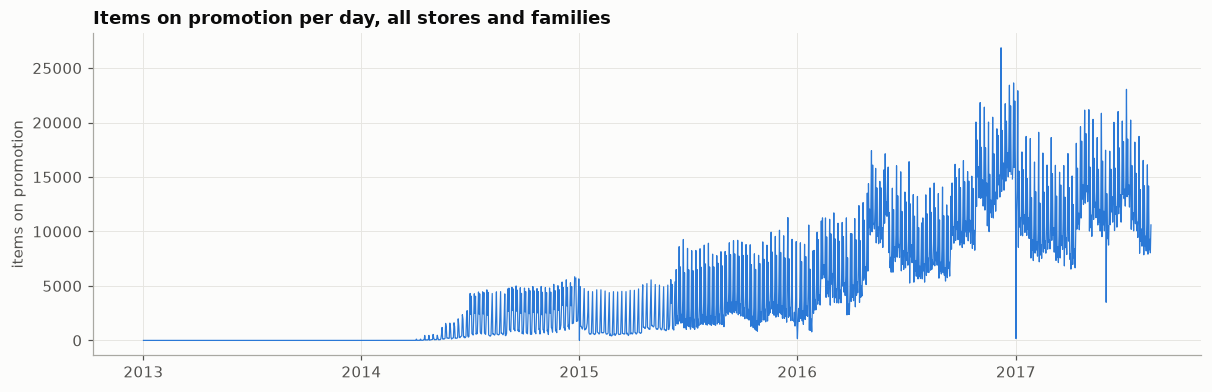

share of rows with a promotion, by year: {2013: 0.0, 2014: 0.1, 2015: 0.209, 2016: 0.351, 2017: 0.453}
mean onpromotion per row: last 16 train days 5.92 | test 6.97


In [20]:
promo_daily = train.groupby("date")["onpromotion"].sum().reindex(CAL)
first_promo = train.loc[train["onpromotion"] > 0, "date"].min()
print("first day with any promotion:", first_promo.date())

fig, ax = plt.subplots(figsize=(13, 3.8))
ax.plot(promo_daily.index, promo_daily.to_numpy(), color=BLUE, lw=0.8)
ax.set(title="Items on promotion per day, all stores and families", ylabel="items on promotion")
save(fig, "promotions_over_time")
plt.show()

share = train.assign(p=train["onpromotion"] > 0).groupby(train["date"].dt.year)["p"].mean()
print("share of rows with a promotion, by year:", share.round(3).to_dict())
last16 = train[train["date"] > cv.TRAIN_END - pd.Timedelta(days=16)]["onpromotion"]
print(f"mean onpromotion per row: last 16 train days {last16.mean():.2f} | test {test['onpromotion'].mean():.2f}")

Promotions start on 2014-04-01, so for the first 15 months onpromotion is zero because the data wasn't recorded, not because nothing was promoted. Their use grows steadily: 10% of rows had a promotion in 2014, 21% in 2015, 35% in 2016 and 45% in 2017. The plot also shows a weekly pattern in promotions themselves.

The test period has more promotions than the end of training: 6.97 items per row against 5.92 in the last 16 days. The models will be asked to predict at promotion levels slightly above what they've seen recently.

any promotion vs none, same series and month: +30.7% sales
elasticity: +1% items on promotion (log1p scale) -> +0.138% sales


/tmp/ipykernel_4106570/2306460670.py:13: RuntimeWarning: invalid value encountered in scalar divide
  return float((df[x + "_dm"] * df["y_dm"]).sum() / (df[x + "_dm"] ** 2).sum())


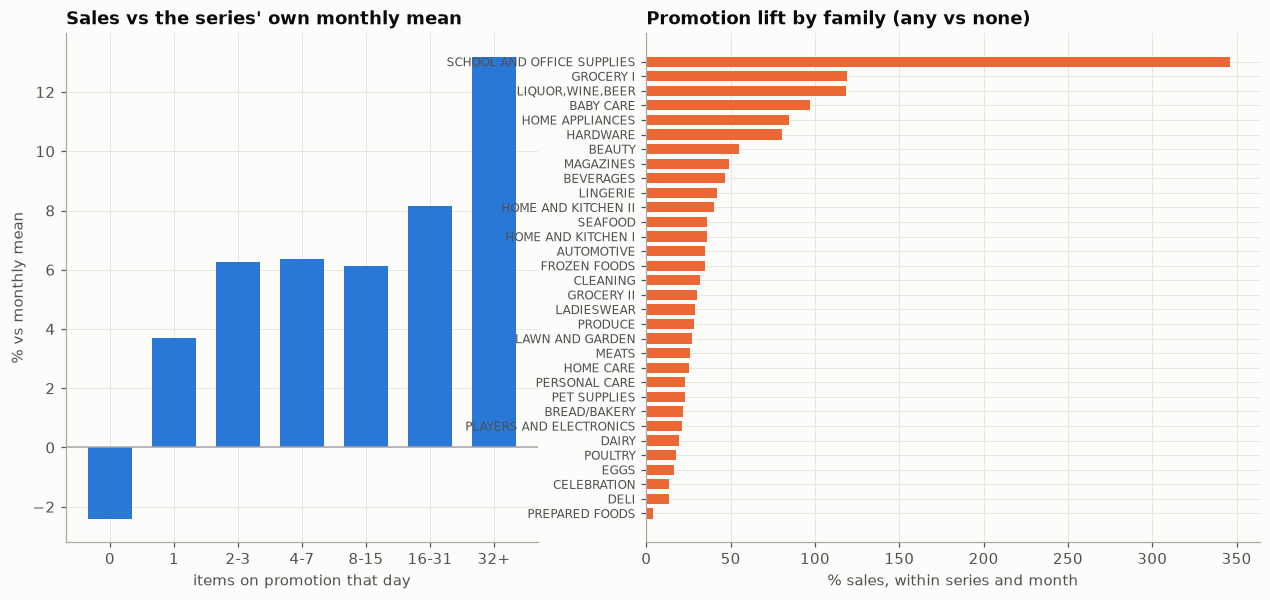

In [21]:
# Within-series promotion effect.
# Compare each series with itself in the same month: demean log sales and the promo variable
# by (store, family, year-month), then regress demeaned y on demeaned x (a fixed-effects estimate).
p = train.loc[train["date"] >= first_promo, ["date", "store_nbr", "family", "sales", "onpromotion"]].copy()
p["y"] = np.log1p(p["sales"])
p["any"] = (p["onpromotion"] > 0).astype("float64")
p["logp"] = np.log1p(p["onpromotion"])
g = p.groupby(["store_nbr", "family", p["date"].dt.to_period("M")])
for c in ["y", "any", "logp"]:
    p[c + "_dm"] = p[c] - g[c].transform("mean")

def fe_slope(df, x):
    return float((df[x + "_dm"] * df["y_dm"]).sum() / (df[x + "_dm"] ** 2).sum())

b_any, b_log = fe_slope(p, "any"), fe_slope(p, "logp")
print(f"any promotion vs none, same series and month: {np.exp(b_any) * 100 - 100:+.1f}% sales")
print(f"elasticity: +1% items on promotion (log1p scale) -> {b_log:+.3f}% sales")

bins = pd.cut(p["onpromotion"], [-1, 0, 1, 3, 7, 15, 31, 10_000], labels=["0", "1", "2-3", "4-7", "8-15", "16-31", "32+"])
by_bin = (np.exp(p.groupby(bins, observed=True)["y_dm"].mean()) - 1) * 100
fam_lift = (np.exp(p.groupby("family").apply(lambda d: fe_slope(d, "any"), include_groups=False)) - 1) * 100
fam_lift = fam_lift.dropna().sort_values()

fig, axes = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={"width_ratios": [1, 1.3]})
axes[0].bar(by_bin.index.astype(str), by_bin.to_numpy(), color=BLUE, width=0.7)
axes[0].axhline(0, color=NEUTRAL, lw=1)
axes[0].set(title="Sales vs the series' own monthly mean", xlabel="items on promotion that day", ylabel="% vs monthly mean")
axes[1].barh(fam_lift.index, fam_lift.to_numpy(), color=[ORANGE if v > 0 else BLUE for v in fam_lift], height=0.7)
axes[1].axvline(0, color=NEUTRAL, lw=1)
axes[1].tick_params(axis="y", labelsize=8)
axes[1].set(title="Promotion lift by family (any vs none)", xlabel="% sales, within series and month")
save(fig, "promotion_effect")
plt.show()
SUMMARY["promo lift, any vs none %"] = round(float(np.exp(b_any)) * 100 - 100, 1)

Within the same series and month, days with any promotion sell about 31% more than days without (elasticity 0.138 on the log1p scale). The binned chart rises with the number of items promoted, from −2% at zero to +13% at 32 or more. Its steps look smaller than 31% because series-months where every day (or no day) has a promotion sit near zero in both bins.

I don't trust the 31% as a causal number, and I think it's too high. Closed days (Jan 1, store closures) have zero promotions and near-zero sales, which inflates the estimate. The data gaps before mid-2015 do the same. Stores also schedule promotions when they already expect demand: SCHOOL AND OFFICE SUPPLIES at +345% most likely reflects back-to-school timing more than the promotion itself. Phase 4's regression, with closures removed and calendar effects controlled, will give a cleaner number.

The RuntimeWarning is a 0/0 for a family whose promotion variable never varies within any month (no promotions at all), so its lift is NaN and is dropped from the chart. It's harmless.

For the models: onpromotion is known for the test days, so it's allowed, and log1p(onpromotion) with a family interaction is the natural form.

## 10 · Oil

oil rows 1218, daily after forward fill 1704, still missing: 1 (first date 2013-01-01, first value 2013-01-02)


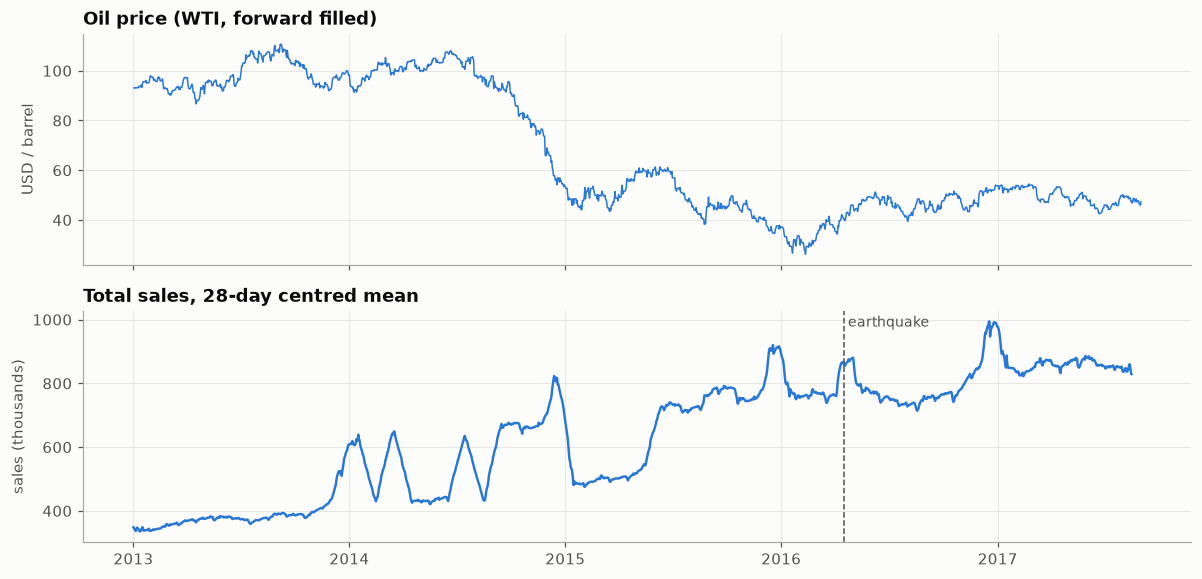

correlation, monthly levels:            -0.79
correlation, month-to-month changes:    +0.05


In [22]:
oil_d = features.daily_oil(oil)
print(f"oil rows {len(oil)}, daily after forward fill {len(oil_d)}, still missing: {int(oil_d.isna().sum())} "
      f"(first date {oil_d.index.min().date()}, first value {oil_d.first_valid_index().date()})")

fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
axes[0].plot(oil_d.index, oil_d.to_numpy(), color=BLUE, lw=1)
axes[0].set(title="Oil price (WTI, forward filled)", ylabel="USD / barrel")
axes[1].plot(total.index, total.rolling(28, center=True, min_periods=14).mean() / 1e3, color=BLUE, lw=1.6)
axes[1].set(title="Total sales, 28-day centred mean", ylabel="sales (thousands)")
mark(axes[1], pd.Timestamp("2016-04-16"), "earthquake")
save(fig, "oil_vs_sales")
plt.show()

monthly = pd.DataFrame({"log_sales": np.log(total.resample("MS").mean()),
                        "oil": oil_d.resample("MS").mean()}).loc[:cv.TRAIN_END].dropna()
c_level = monthly.corr().iloc[0, 1]
c_diff = monthly.diff().dropna().corr().iloc[0, 1]
print(f"correlation, monthly levels:            {c_level:+.2f}")
print(f"correlation, month-to-month changes:    {c_diff:+.2f}")
SUMMARY["oil corr: levels / changes"] = (round(float(c_level), 2), round(float(c_diff), 2))

Oil collapsed from about $100 to $50 in late 2014 and has stayed between $30 and $55 since. Over the same period sales rose. In monthly levels that gives a correlation of −0.79, which looks impressive, but in month-to-month changes it's +0.05, i.e. nothing.

This is the classic spurious regression. Two series that both trend will correlate in levels whether or not they're related, and the honest test is whether their changes move together. Here they don't. On top of that, the oil column runs to Aug 31, but at forecast time I wouldn't know those prices.

Decision: oil stays out of the main models. At most I'll try a lagged oil feature once in Phase 6 and keep it only if the backtest improves. Only one value is still missing after the forward fill (2013-01-01, the first day), and that's fine.

## 11 · Transactions

train days with no transactions at all: [datetime.date(2016, 1, 1), datetime.date(2016, 1, 3)]
total sales on those days: {Timestamp('2016-01-01 00:00:00'): 16.4, Timestamp('2016-01-03 00:00:00'): 1226.7}

store-days with sales > 0 but no transactions row: 118
store-days with transactions but zero sales: 0

corr(log sales, log transactions): pooled +0.84 | within store +0.59


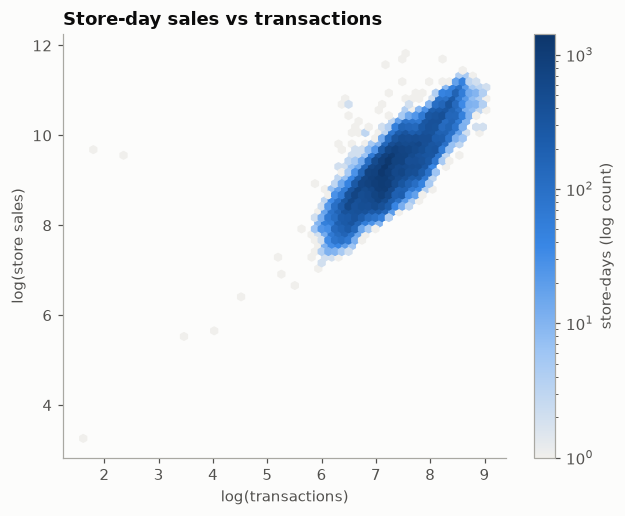


transactions end on 2017-08-15 - test starts 2017-08-16


In [23]:
train_days = pd.DatetimeIndex(train["date"].unique())
no_trans_days = train_days.difference(pd.DatetimeIndex(trans["date"].unique()))
print("train days with no transactions at all:", [d.date() for d in no_trans_days])
print("total sales on those days:", (total.reindex(no_trans_days) / 1e3).round(1).to_dict())

st_long = ST.stack().rename("store_sales").reset_index()
st_long.columns = ["date", "store_nbr", "store_sales"]
m = st_long.merge(trans, on=["date", "store_nbr"], how="left")
print("\nstore-days with sales > 0 but no transactions row:", int(((m["store_sales"] > 0) & m["transactions"].isna()).sum()))
print("store-days with transactions but zero sales:", int(((m["store_sales"] == 0) & m["transactions"].notna()).sum()))

mm = m[(m["store_sales"] > 0) & (m["transactions"] > 0)].copy()
mm["ls"], mm["lt"] = np.log(mm["store_sales"]), np.log(mm["transactions"])
pooled = mm[["ls", "lt"]].corr().iloc[0, 1]
dm = mm[["ls", "lt"]] - mm.groupby("store_nbr")[["ls", "lt"]].transform("mean")
within = dm.corr().iloc[0, 1]
print(f"\ncorr(log sales, log transactions): pooled {pooled:+.2f} | within store {within:+.2f}")

fig, ax = plt.subplots(figsize=(6.5, 5))
hb = ax.hexbin(mm["lt"], mm["ls"], gridsize=60, cmap=SEQ, mincnt=1, bins="log")
ax.grid(False)
ax.set(title="Store-day sales vs transactions", xlabel="log(transactions)", ylabel="log(store sales)")
fig.colorbar(hb, ax=ax, label="store-days (log count)")
save(fig, "transactions")
plt.show()
print("\ntransactions end on", trans["date"].max().date(), "- test starts", cv.TEST_START.date())
SUMMARY["transactions corr: pooled / within store"] = (round(float(pooled), 2), round(float(within), 2))

Two training days have no transactions for any store. 2016-01-01 is a closure, which is fine. 2016-01-03 is a normal day with 1.23 million in sales, so its transactions are simply missing. Another 118 store-days have sales but no transactions row.

Transactions track sales closely (0.84 pooled; 0.59 within a store, which is the more honest number), and that's exactly the trap. They stop on 2017-08-15, so using same-day transactions would be using the answer. A lagged version (16+ days) would be allowed, but it says little that the sales lags don't already say.

Decision: transactions are not used as a feature.

## 12 · Decomposition: MSTL on log total sales

Decompose log(total) = trend + weekly + yearly + remainder. On the log scale an additive decomposition is a
multiplicative one on sales, which matches how the weekly swing grows with the level.

Dec 25 (no data) and Jan 1 (stores closed, about −4 in log units) are interpolated for sections 12–14 only.
They are known calendar closures that will be handled by explicit features. Left in, Jan 1 takes over the
yearly component, and the leap year pushes Jan 1 2017 into the remainder. `robust=True` limits the pull
of the remaining one-off days (the earthquake, other holidays).

Strength of a component (Hyndman): F = max(0, 1 − Var(remainder) / Var(component + remainder)). Near 1 = strong.

MSTL fitted in 6.2s


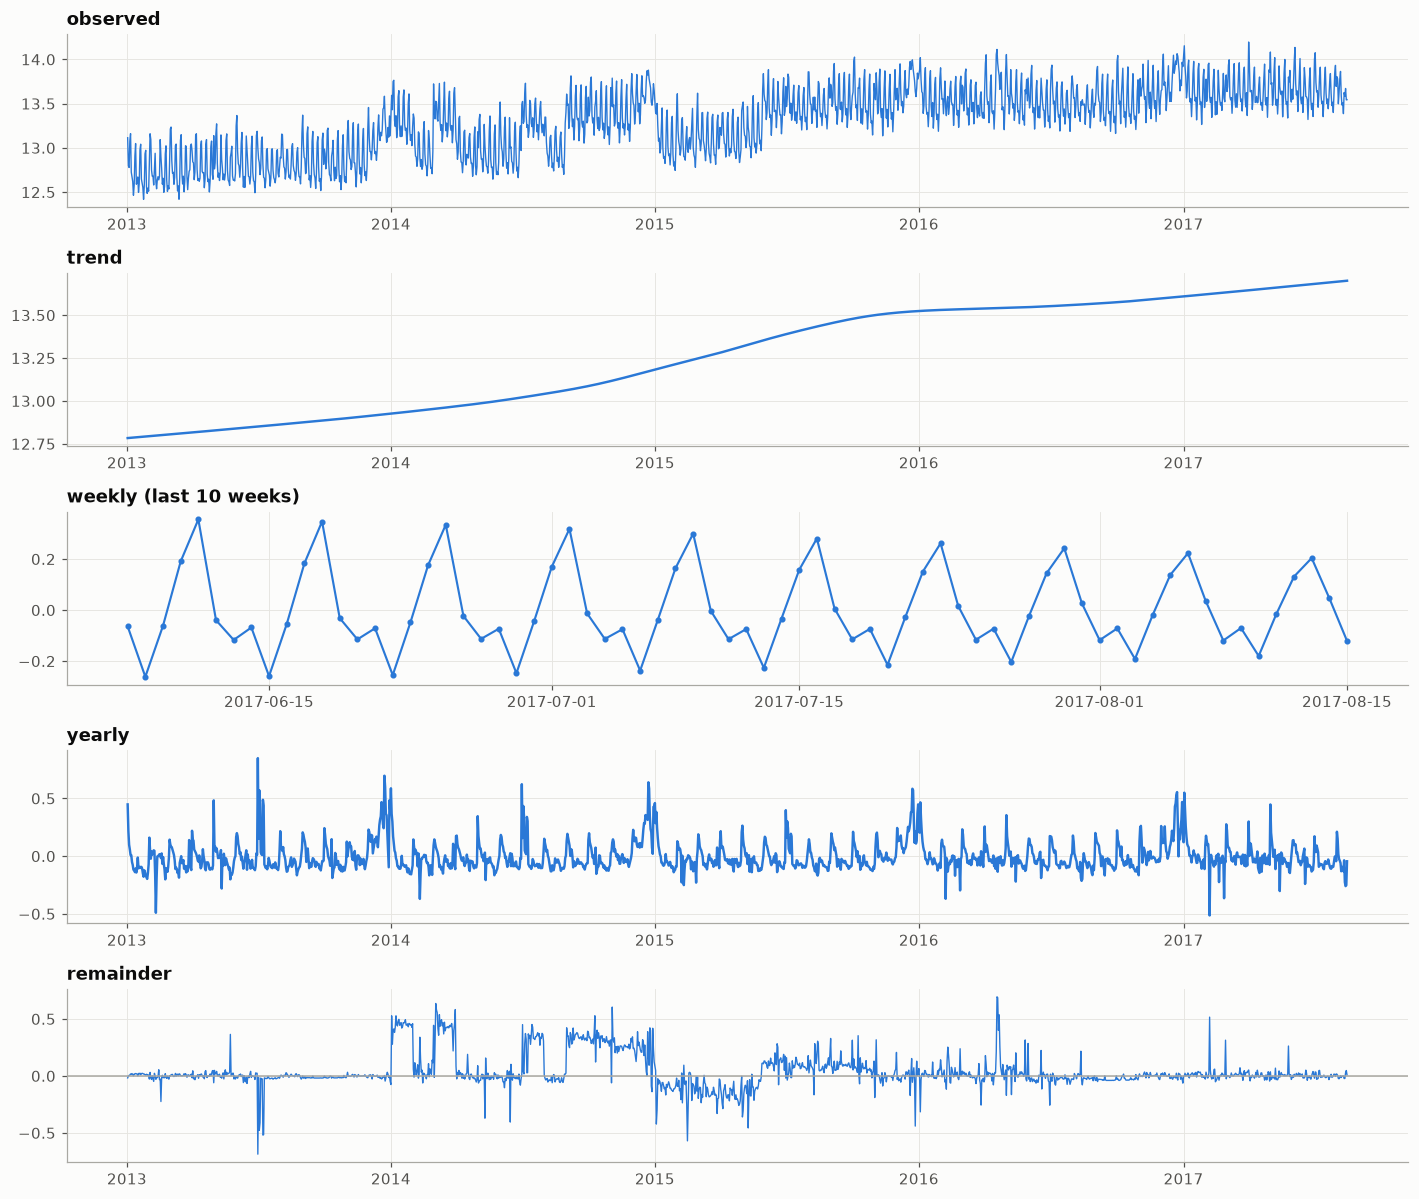

strength: {'trend': 0.79, 'weekly': 0.59, 'yearly': 0.35}
largest remainders (log units):
2016-04-18   0.6900
2016-04-19   0.6900
2013-07-01   0.6900
2014-03-04   0.6400
2014-11-03   0.6000
2014-03-31   0.5800
2014-03-05   0.5800
2015-02-15   0.5700


In [24]:
jan1 = (log_total.index.month == 1) & (log_total.index.day == 1)
y = log_total.mask(jan1).interpolate(limit_area="inside")     # Dec 25 and Jan 1 interpolated
y = y.loc[y.first_valid_index():]                               # the series starts on a Jan 1: begin on Jan 2
assert y.notna().all() and y.index.freq is not None
t0 = time.perf_counter()
res = MSTL(y, periods=(7, 365), stl_kwargs={"robust": True}).fit()
print(f"MSTL fitted in {time.perf_counter() - t0:.1f}s")
comp = pd.DataFrame({"observed": y, "trend": res.trend, "weekly": res.seasonal["seasonal_7"],
                     "yearly": res.seasonal["seasonal_365"], "remainder": res.resid})

fig, axes = plt.subplots(5, 1, figsize=(13, 11))
for ax, c in zip(axes, comp.columns):
    if c == "weekly":
        w = comp[c].iloc[-70:]
        ax.plot(w.index, w.to_numpy(), color=BLUE, lw=1.4, marker="o", ms=3)
        ax.set_title("weekly (last 10 weeks)")
    else:
        ax.plot(comp.index, comp[c].to_numpy(), color=BLUE, lw=0.9 if c in ("observed", "remainder") else 1.6)
        ax.set_title(c)
axes[-1].axhline(0, color=NEUTRAL, lw=1)
fig.tight_layout()
save(fig, "mstl")
plt.show()

def strength(component, remainder):
    return max(0.0, 1 - np.var(remainder) / np.var(component + remainder))
F = {"trend": strength(comp["trend"], comp["remainder"]),
     "weekly": strength(comp["weekly"], comp["remainder"]),
     "yearly": strength(comp["yearly"], comp["remainder"])}
print("strength:", {k: round(float(v), 2) for k, v in F.items()})
print("largest remainders (log units):")
print(comp["remainder"].abs().nlargest(8).round(2).to_string())
SUMMARY["MSTL strength trend / weekly / yearly"] = tuple(round(float(v), 2) for v in F.values())

Strengths: trend 0.79, weekly 0.59, yearly 0.35. These are lower than I expected for a retail series, and the remainder panel shows why: it has blocks at +0.5 through 2014 and below zero in early 2015. Those blocks are the data gaps, and MSTL has nowhere to put them except the remainder. From mid-2015 the remainder is small and quiet. So the weekly strength on clean data would be clearly higher, and the yearly strength is diluted by noise.

The largest remainders confirm it: 2016-04-18/19 (earthquake), 2013-07-01, and days in March 2014, November 2014 and February 2015 (data on/off edges and Carnaval).

The weekly component is the cleanest part: a regular shape every week, with the Sunday peak shrinking slightly over the last 10 weeks. The yearly component is spiky because the 365-day cycle also picks up the start-of-month peaks.

## 13 · Stationarity: ADF and KPSS

The two tests have opposite null hypotheses, so they're read together:

- ADF: H0 = unit root (non-stationary). A small p-value says stationary.
- KPSS: H0 = stationary. A small p-value says non-stationary.

KPSS only reports p-values between 0.01 and 0.10; outside that range statsmodels returns the bound and warns, so those show as ≤0.01 or ≥0.10.

In [25]:
def kpss_p(s, regression="c"):
    with warnings.catch_warnings(record=True) as w:
        warnings.simplefilter("always", InterpolationWarning)
        stat, pval, *_ = kpss(s, regression=regression, nlags="auto")
    bounded = any(issubclass(x.category, InterpolationWarning) for x in w)
    return stat, pval, bounded

def read(adf_p, kpss_pv):
    a, k = adf_p < 0.05, kpss_pv <= 0.05
    if a and not k: return "stationary"
    if not a and k: return "non-stationary (unit root)"
    if a and k:     return "conflict: trend-stationary / breaks"
    return "inconclusive"

transforms = {
    "log total": y,
    "diff 1": y.diff(1),
    "diff 7 (weekly)": y.diff(7),
    "diff 7 then diff 1": y.diff(7).diff(1),
}
rows = []
for name, s in transforms.items():
    s = s.dropna()
    for reg in (["c", "ct"] if name == "log total" else ["c"]):
        adf_stat, adf_p, adf_lags, *_ = adfuller(s, regression=reg, autolag="AIC", result_object=False)
        k_stat, k_p, k_b = kpss_p(s, "c" if reg == "c" else "ct")
        rows.append({"series": name, "deterministic": reg, "ADF stat": adf_stat, "ADF p": adf_p, "ADF lags": adf_lags,
                     "KPSS stat": k_stat, "KPSS p": (("≤" if k_p <= 0.01 else "≥") if k_b else "") + f"{k_p:.3f}",
                     "reading": read(adf_p, k_p)})
print(pd.DataFrame(rows).round(3).to_string(index=False))

            series deterministic  ADF stat  ADF p  ADF lags  KPSS stat KPSS p                             reading
         log total             c   -2.4270 0.1340        25     5.4210 ≤0.010          non-stationary (unit root)
         log total            ct   -4.8410 0.0000        25     0.4080 ≤0.010 conflict: trend-stationary / breaks
            diff 1             c  -11.6450 0.0000        25     0.0190 ≥0.100                          stationary
   diff 7 (weekly)             c  -10.8900 0.0000        23     0.0170 ≥0.100                          stationary
diff 7 then diff 1             c  -15.0590 0.0000        25     0.0120 ≥0.100                          stationary


log total: with only a constant, ADF can't reject a unit root (p = 0.13) and KPSS rejects stationarity (p ≤ 0.01), so it's non-stationary. With a trend added, ADF rejects (p < 0.001) but KPSS still rejects. Both rejecting usually means a trend plus structural breaks, and here the breaks are the 2014–2015 data gaps and the mid-2015 step.

All three differenced versions are clearly stationary (ADF p ≈ 0, KPSS p ≥ 0.10). One difference is enough, either a first difference (d = 1) or a weekly difference (D = 1, period 7). Doing both risks over-differencing. For SARIMA in Phase 5 I'll start from D = 1 at period 7, because the weekly pattern is the dominant structure, and let AIC and the backtest decide whether d = 1 is needed on top.

In [26]:
# The same two tests on every individual series: log1p(sales), last two years
t0 = time.perf_counter()
L = np.log1p(W.loc[cv.TRAIN_END - pd.Timedelta(days=729):]).interpolate(limit_area="inside")
L = L.loc[:, L.std() > 0]
out = []
for col in L.columns:
    s = L[col].dropna()
    adf_p = adfuller(s, regression="c", maxlag=14, autolag="AIC", result_object=False)[1]
    k_p = kpss_p(s, "c")[1]
    out.append(read(adf_p, k_p))
series_read = pd.Series(out, index=L.columns)
print(f"tested {len(L.columns)} non-constant series in {time.perf_counter() - t0:.0f}s")
print(series_read.value_counts().to_string())
SUMMARY["series reading (last 2y)"] = series_read.value_counts().to_dict()

tested 1725 non-constant series in 17s
conflict: trend-stationary / breaks    946
stationary                             610
non-stationary (unit root)             142
inconclusive                            27


Across 1,725 non-constant series (last two years): 946 have both tests rejecting, 610 look stationary, 142 non-stationary and 27 inconclusive. The large "both reject" group isn't telling me much. With 730 observations both tests reject easily, and many series contain breaks (store closures, families that start or stop, store 52 opening).

So per-series unit-root tests aren't a reliable way to choose differencing for 1,782 series. I'll choose by AIC and the backtest instead.

## 14 · ACF and PACF

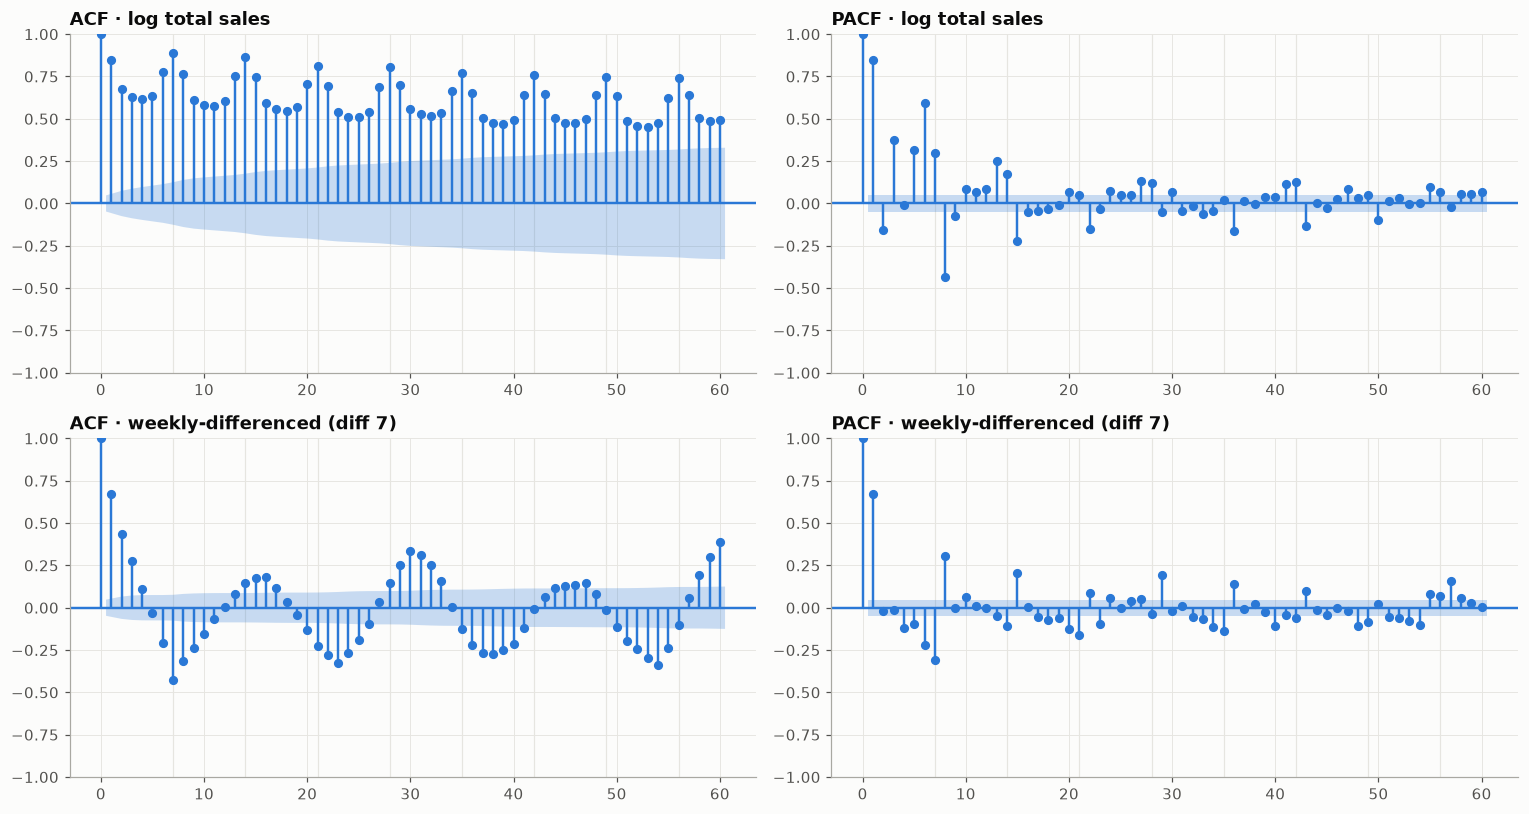

In [27]:
fig, axes = plt.subplots(2, 2, figsize=(14, 7.5))
plot_acf(y, lags=60, ax=axes[0, 0], title="ACF · log total sales")
plot_pacf(y, lags=60, ax=axes[0, 1], method="ywm", title="PACF · log total sales")
d7 = y.diff(7).dropna()
plot_acf(d7, lags=60, ax=axes[1, 0], title="ACF · weekly-differenced (diff 7)")
plot_pacf(d7, lags=60, ax=axes[1, 1], method="ywm", title="PACF · weekly-differenced (diff 7)")
for ax in axes.flat:
    for k in (7, 14, 21, 28, 35, 42, 49, 56):
        ax.axvline(k, color=GRID, lw=0.8, zorder=0)
fig.tight_layout()
save(fig, "acf_pacf_total")
plt.show()

On log total, the ACF decays very slowly with peaks every 7 lags: non-stationary with strong weekly seasonality, consistent with the tests.

After weekly differencing:
- the ACF starts at 0.67 at lag 1 and decays over a few lags, which is the signature of an AR(1) term;
- there's a clear negative spike at lag 7 (−0.43), typical of a seasonal MA(1) after a seasonal difference;
- a wave runs through all the lags, peaking at about 16, 31, 46 and 60, i.e. a cycle of about half a month, matching two paydays a month;
- the PACF cuts off after lag 1, with smaller spikes near 7–8.

A reasonable starting point for Phase 5 is SARIMA(1,0,0)(0,1,1)[7] on log total, with day-of-month, payday and holiday regressors to absorb the half-month wave.

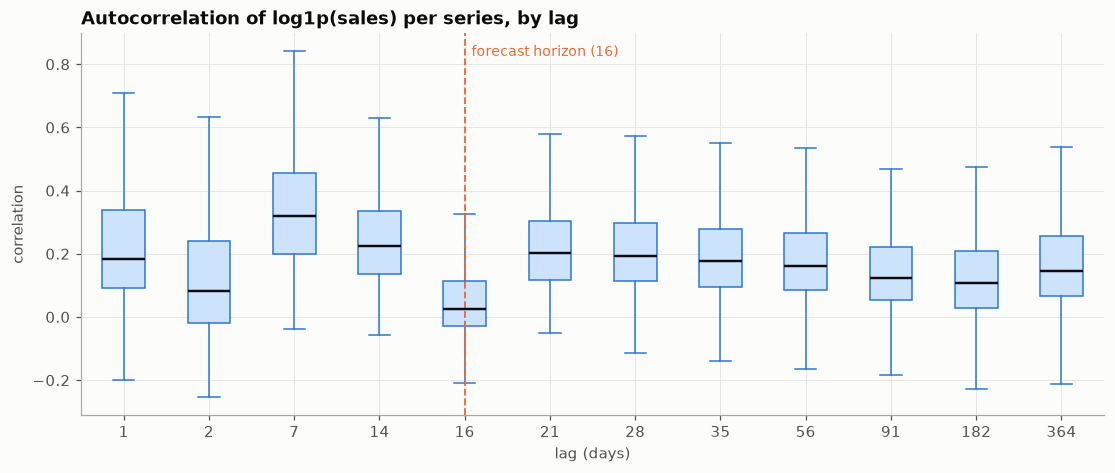

1     0.1850
2     0.0810
7     0.3180
14    0.2260
16    0.0270
21    0.2010
28    0.1940
35    0.1780
56    0.1620
91    0.1230
182   0.1080
364   0.1460


In [28]:
# Autocorrelation at chosen lags across all 1,782 series (log1p sales, last two years).
# W is on the full calendar, so shift(k) is exactly k days.
lags = [1, 2, 7, 14, 16, 21, 28, 35, 56, 91, 182, 364]
Lr = np.log1p(W.loc[cv.TRAIN_END - pd.Timedelta(days=729):])
Lr = Lr.loc[:, Lr.std() > 0]
ac = pd.DataFrame({k: Lr.corrwith(Lr.shift(k)) for k in lags})

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.boxplot([ac[k].dropna() for k in lags], tick_labels=[str(k) for k in lags], showfliers=False,
           patch_artist=True, boxprops={"facecolor": "#cde2fb", "edgecolor": BLUE},
           medianprops={"color": INK, "lw": 1.6}, whiskerprops={"color": BLUE}, capprops={"color": BLUE})
ax.axvline(lags.index(16) + 1, color=ORANGE, lw=1.2, ls="--")
ax.text(lags.index(16) + 1.08, 0.97, "forecast horizon (16)", color=ORANGE, fontsize=9, transform=ax.get_xaxis_transform(), va="top")
ax.set(title="Autocorrelation of log1p(sales) per series, by lag", xlabel="lag (days)", ylabel="correlation")
save(fig, "series_autocorrelation")
plt.show()
print(ac.median().round(3).rename("median across series").to_string())
SUMMARY["median series autocorr lag 1 / 7 / 16 / 21"] = tuple(round(float(ac[k].median()), 2) for k in (1, 7, 16, 21))

This plot decides how the lag features should look. Per series, lag 7 has the highest autocorrelation (median 0.32), then lag 14 (0.23), lag 21 (0.20) and lag 28 (0.19). Lag 1 is only 0.19, because individual store-family series are noisy day to day. Lag 16 is almost useless (0.03), and lag 2 is weak too (0.08). What matters is being the same weekday, not being recent.

With a 16-day horizon a direct model can't use lag 7 or 14 for the later days. Lag 16 lands two days off the weekday and carries almost nothing. So the useful lags are 21, 28, 35… (same weekday, all at least 16 days back), plus rolling means that end 16+ days back and weekday-specific rolling means. Another option is horizon-specific models where days 1–7 can use lag 7. Lag 364 (0.15) adds a little yearly memory, but only where a full clean year exists.

## 15 · Key numbers

In [29]:
for k, v in SUMMARY.items():
    print(f"{k:48s} {v}")
print(f"\nnotebook run time: {time.perf_counter() - T0:.0f}s")

mean daily sales 2016 / 2013                     2.05
weekday range (max/min), last full year          1.64
December / average month                         1.35
payday day 0 / day 1 effect %                    (1.9, 14.6)
local holiday effect, matched stores %           -2.9
earthquake: total, 4 weeks after, % vs 2015      11.2
top 3 families, % of sales                       63.6
stores opening after Feb 2013                    8
series always zero                               53
series zero in last 28 days of train             114
promo lift, any vs none %                        30.7
oil corr: levels / changes                       (-0.79, 0.05)
transactions corr: pooled / within store         (0.84, 0.59)
MSTL strength trend / weekly / yearly            (0.79, 0.59, 0.35)
series reading (last 2y)                         {'conflict: trend-stationary / breaks': 946, 'stationary': 610, 'non-stationary (unit root)': 142, 'inconclusive': 27}
median series autocorr lag 1 / 7 / 16 / 21  

The whole notebook ran in 61 seconds.

## Findings → decisions

1. **The data before about June 2015 has recording gaps.** Ten families (eleven with BABY CARE) have no data in 2013, switch on and off in 2014, and are blank again from January to about May 2015. Their zeros are missing records, not demand. *Decision:* in Phase 2, find the exact date after which every family is recorded continuously, and train the models from there (about 26 months, which still includes one full year for yearly effects). Where earlier data is kept (for example for classical models on the total), the gap periods are treated as missing, never as zero.
2. **8.1% of all rows are "store not open" zeros** (before opening, long closures, Jan 1). *Decision:* `clean()` marks closed store-days as missing for training and for every lag/rolling window. All 54 stores are open in the test period.
3. **The target is log1p(sales), scored with RMSLE.** 31% zeros, skew 7.4 → 0.41 after log1p, whole units for most families and weights for a few. Every model predicts log1p and is scored back on the sales scale.
4. **Dead series:** 53 never sell, 114 sold nothing in the last 28 days. Zero for 56 days → 92.5–100% stay zero for the next 16. *Decision:* a zero rule becomes a model component in Phase 3, with the lookback chosen through the backtest.
5. **Weekly seasonality is the strongest effect** (Sunday about 1.30×, Thursday about 0.79×, stable across years) and differs by family (LIQUOR is lowest on Sunday, EGGS highest on Monday). *Decision:* day of week, with day-of-week × family terms in linear models.
6. **Monthly cycle:** the 1st is about +26%, decaying to about −7% around the 25th–28th, with a small bump on the 16th and the last day. *Decision:* day-of-month features plus flags for the 15th/16th and the month end, not just "days since payday".
7. **Yearly:** clean only in December (1.25–1.41×, peak Dec 23). Jan 1 is near zero every year, and Jan 2 rebounds. *Decision:* explicit Dec 23/24, Dec 26–31, Jan 1 and Jan 2 features. The Jan 1 closure is a calendar rule, not taken from the holidays file (2017 shows why). Low-order Fourier terms for the rest of the year, fitted on the clean period only.
8. **Holidays:** effects measured one at a time are confounded with the month start and the December ramp. Local holidays are about −3% in the matching stores, regional ones about 0. One local holiday in test (Ambato, Aug 24, stores 23 and 50). *Decision:* collapse the file per date and locale; transferred → the effect goes on the Transfer date; Bridge = holiday; Work Day = normal day; match regional/local holidays by state/city; estimate all the effects together in the Phase 4 regression.
9. **The earthquake:** about +11% for four weeks, with extreme bulk purchases in GROCERY I (124,717 on 2016-05-02). *Decision:* an earthquake period flag (2016-04-16 to about mid-May) or that period left out of training. Two other extreme values (store 39 MEATS 2016-10-07, store 44 GROCERY I 2013-11-12) get checked in `clean()`.
10. **Promotions:** known in advance, so they're allowed. +31% within series and month, but that's an upper bound (closures, data gaps, promotion timing). Test has more promotions than the end of training (6.97 vs 5.92 per row). *Decision:* log1p(onpromotion), with family interactions.
11. **Oil:** −0.79 correlation in levels, +0.05 in changes, a spurious regression. *Decision:* left out; possibly one lagged test in Phase 6. Future oil values are never used.
12. **Transactions:** strongly tied to sales but missing for the test period. *Decision:* not used.
13. **Stationarity:** log total is non-stationary with breaks; any single difference makes it stationary. Per-series tests mostly say "both reject" and aren't useful for 1,782 series. *Decision:* SARIMA starts from D = 1 at period 7, and AIC and the backtest choose the orders.
14. **ACF/PACF after a weekly difference:** AR(1)-like decay, a seasonal MA spike at lag 7, a half-month (payday) wave. *Decision:* SARIMA(1,0,0)(0,1,1)[7] with calendar regressors as the Phase 5 starting point.
15. **Lags:** same weekday matters more than recency (lag 7: 0.32, lag 16: 0.03, lag 21: 0.20). *Decision:* direct models use lags 21, 28, 35… plus rolling means that end at least 16 days back (weekday-specific ones too). Horizon-specific or recursive models can use lag 7 for the first days.

## Where I am

The EDA is done and it changed my plan more than I expected. The big surprise wasn't a seasonal pattern but a data problem. Ten product families weren't recorded in 2013 and come and go until about mid-2015, so a lot of what looks like trend and yearly seasonality in the early years is really data coverage. On top of that, 8.1% of all rows are days when a store wasn't open. Both kinds of zero have to be marked as missing rather than learned as demand. The real signal is clear once those are set aside: a strong weekly pattern that differs a bit by family, a start-of-month spending cycle, a December peak with a Jan 1 closure, a meaningful promotion effect, and lags that work by weekday rather than by recency, which shapes how the 16-day horizon has to be handled. Oil and transactions are out. I also now have a concrete starting point for SARIMA and a list of features for the regression.

Next is Phase 2, feature engineering without leakage. I'll write `clean()` to find the exact clean start date, mark closures and data gaps as missing, and decide on the two suspicious extreme values. Then come the calendar features (day of week, day of month, month-start and payday flags, December and Jan 1/2 flags, yearly Fourier terms), holidays matched to each store's city and state with transfers handled, the earthquake flag, promotion features, and lag and rolling features at 21, 28 and 35 days and beyond, all computed on the full calendar and shifted so they only use the past. Each feature family gets a check that it never looks past the cutoff.